---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 01: Task 1 (Data Understanding and Preprocessing) dan Task 2 (Conference Popularity Analysis).*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)

**[Part I: Task 1, Data Understanding and Preprocessing](#part1)**

3. [**Eksplorasi Dataset (Task 1.1)**](#3)
4. [**Preprocessing (Task 1.2 dan 1.3)**](#4)
5. [**Statistik Dataset Bersih (Task 1.4)**](#5)

**[Part II: Task 2, Conference Popularity Analysis](#part2)**

6. [**Analisis Popularitas Konferensi (Task 2)**](#6)
7. [**Ringkasan dan Langkah Berikutnya**](#7)

---

# Introduction <a name="1"></a>

---

## Overview

*DBLP (Digital Bibliography and Library Project) adalah basis data bibliografi ilmu komputer yang mencatat judul, author, tahun, dan venue setiap publikasi. Notebook ini mengerjakan Task 1 tugas besar Data Mining, yaitu memahami struktur dataset DBLP dan menyiapkan datanya untuk Frequent Pattern Mining dan Association Rule Mining pada task berikutnya.*

*Popularitas konferensi pada proyek ini diukur dari aktivitas publikasi, yaitu jumlah publikasi dan jumlah author unik. Setelah data siap, Task 2 pada notebook yang sama menganalisis konferensi mana yang paling aktif, bagaimana peringkatnya berubah menurut dua ukuran tersebut, dan bagaimana aktivitasnya bergerak selama 2015-2025.*

## Aim

*Task 1.1: menjelaskan struktur dataset, atribut, jumlah record, dan jenis publikasi yang tersedia.*

*Task 1.2 dan 1.3: melakukan preprocessing (memilih konferensi dan workshop, menangani missing values, menghapus duplikat, menormalisasi author dan venue, serta memastikan konsistensi tahun) dan menjelaskan alasan setiap tahap.*

*Task 1.4: menampilkan statistik dataset bersih, yaitu total publikasi, author unik, venue unik, distribusi per tahun, dan distribusi per konferensi.*

*Task 2: mengidentifikasi 10 konferensi dengan publikasi terbanyak dan 10 konferensi dengan author unik terbanyak, menganalisis tren publikasi per tahun, membandingkan kedua peringkat, lalu menjawab konferensi mana yang paling populer, apakah konferensi dengan publikasi terbanyak juga memiliki author unik terbanyak, dan bagaimana aktivitasnya berubah.*

## Metric

***Jumlah publikasi** adalah banyaknya paper `inproceedings` setelah preprocessing. **Author unik** adalah banyaknya nama author berbeda, dan **venue unik** adalah banyaknya konferensi berbeda yang diidentifikasi dari `key` DBLP.*

***Retensi** menunjukkan seberapa besar data yang bertahan setelah preprocessing, sedangkan **CAGR** (compound annual growth rate) meringkas laju pertumbuhan publikasi per tahun pada periode lengkap 2015-2024.*

$$\text{Retensi} = \frac{N_{\text{bersih}}}{N_{\text{mentah}}}
\qquad
\text{CAGR} = \left(\frac{N_{2024}}{N_{2015}}\right)^{1/9} - 1$$

*Pada Task 2, peringkat konferensi disusun menurut dua ukuran, yaitu jumlah publikasi dan jumlah author unik. Ukuran ketiga, **paper per author**, menunjukkan seberapa sering author yang sama kembali menerbitkan karya di sebuah konferensi, dengan pembilang jumlah pasangan paper-author dan penyebut jumlah author unik di konferensi tersebut.*

$$\text{Paper per author} = \frac{\text{jumlah pasangan paper-author di venue}}{\text{jumlah author unik di venue}}$$

## Dataset

*Data bersumber dari DBLP di: https://dblp.org/xml/*

*Dump XML diunduh pada 19 November 2026 (`dblp.xml.gz`, sekitar 1,1 GB, beserta `dblp.dtd`). Dump memuat 13.127.979 record dari sembilan jenis publikasi, dan 2.004.202 di antaranya adalah `inproceedings` pada 2015-2025. Ekstraksi dikerjakan pada notebook `00_extract`.*

*Dataset dipakai untuk mencari konferensi dengan aktivitas publikasi tertinggi dan pola konferensi yang sering dipilih oleh author yang sama.*

**Attributes**

1.  `key`        : ID unik record, mis. `conf/kdd/ChenG16` (atribut XML)
2.  `author`     : nama author, berulang satu tag per orang
3.  `title`      : judul publikasi
4.  `year`       : tahun publikasi
5.  `booktitle`  : nama acara sebagaimana tertulis pada prosiding
6.  `crossref`   : rujukan ke record `proceedings` induk

**Atribut turunan**

`venue` : konferensi tempat paper terbit, diturunkan dari segmen kedua `key` (bukan tag XML)

## Approach: Eksplorasi, Preprocessing, lalu Statistik

*Notebook ini membaca tabel mentah hasil `00_extract`, menjelaskan kondisinya, membersihkannya dalam enam tahap, lalu menghitung statistik pada data bersih. Setiap tahap menyimpan hasilnya ke disk dan tahap berikutnya hanya membaca, sehingga bagian statistik dapat dijalankan ulang tanpa mengulang preprocessing.*

*Pemilihan jenis chart mengikuti panduan Datawrapper (https://www.datawrapper.de/blog/chart-types-guide). Perkembangan waktu memakai column chart dengan garis tren dan small multiples, angka absolut memakai bar, lollipop, dan dumbbell chart, komposisi memakai stacked column dan waffle chart, perubahan peringkat memakai slope chart, hubungan dua ukuran memakai scatter plot, pola banyak kategori sepanjang waktu memakai heatmap, dan alur seleksi data memakai sankey diagram.*

```
inproceedings_raw.parquet            (00_extract)
    |
    +-- Part I: Task 1
    |     3. Eksplorasi: struktur, jenis publikasi, kondisi data
    |     4. Preprocessing: tahun, missing, seleksi conf/, venue, duplikat, author
    |           -> inproceedings_clean.parquet, paper_author.parquet
    |     5. Statistik: total, per tahun, per konferensi, per author
    |
    +-- Part II: Task 2
    |     6. Popularitas konferensi: top 10, tren, perbandingan peringkat
    |     7. Ringkasan dan langkah berikutnya
```

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Seluruh sel dapat dijalankan dalam beberapa menit pada Mac dengan RAM 16 GB. Prasyaratnya adalah notebook `00_extract` sudah dijalankan sehingga `data/processed/inproceedings_raw.parquet` tersedia.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q numpy pandas matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel.

In [2]:
import json
import os
import random
import re
import unicodedata
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch, Rectangle
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FuncFormatter

## Seed Everything

Analisis pada notebook ini bersifat deterministik, tetapi seed tetap ditetapkan agar seluruh notebook dalam proyek ini seragam.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, rentang tahun, dan warna dipusatkan di kelas `Settings`. Palet warna mengikuti palet referensi skill dataviz: satu warna biru sebagai aksen utama, jingga untuk penekanan, dan abu-abu untuk konteks.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    RAW_DIR = ROOT / "data" / "raw"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"

    RAW_PARQUET = PROC_DIR / "inproceedings_raw.parquet"
    CLEAN_PARQUET = PROC_DIR / "inproceedings_clean.parquet"
    PAPER_AUTHOR_PARQUET = PROC_DIR / "paper_author.parquet"

    YEAR_MIN = 2015
    YEAR_MAX = 2025
    YEAR_INCOMPLETE = 2025

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    AQUA = "#1baf7a"
    GRAY = "#b9b8b2"
    ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]

CFG = Settings()
CFG.TAB_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

Gaya grafik dan beberapa fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan laporan berbahasa Indonesia.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)


def id_ticks(ax, axis="y"):
    formatter = FuncFormatter(lambda v, _: fmt_id(v, 0 if float(v).is_integer() else 1))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)

## Load Dataset

Berkas hasil `00_extract` dibaca di sini: tabel mentah, identitas dump, hitungan jenis publikasi, dan judul prosiding setiap venue. Tidak ada visualisasi pada tahap ini.

In [6]:
dump_info = json.loads((CFG.PROC_DIR / "dump_info.json").read_text(encoding="utf-8"))

record_types = (
    pd.read_csv(CFG.TAB_DIR / "record_types_all.csv", index_col="type").rename(columns={"n": "seluruh_dblp"})
    .join(pd.read_csv(CFG.TAB_DIR / "record_types_2015_2025.csv", index_col="type").rename(columns={"n": "periode"}))
    .fillna(0).astype(int)
)
venue_proceedings = pd.read_csv(CFG.PROC_DIR / "venue_proceedings.csv")
raw = pd.read_parquet(CFG.RAW_PARQUET)

print(f"Dump diunduh : {dump_info['downloaded_at']}")
print(f"Total record : {dump_info['total_records']:,}")
print(f"Data mentah  : {len(raw):,} baris x {raw.shape[1]} kolom")

Dump diunduh : 2026-11-19T02:19Z
Total record : 13,127,979
Data mentah  : 2,004,202 baris x 6 kolom


---

---

# PART I | TASK 1: Data Understanding and Preprocessing <a name="part1"></a>

*Memahami struktur dataset DBLP, membersihkannya, dan menghitung statistik dataset bersih.*

---

---

---

# Eksplorasi Dataset (Task 1.1) <a name="3"></a>

---

Bagian ini menjawab Task 1.1: bentuk file dan struktur record DBLP, atribut yang tersedia, jumlah record, dan jenis publikasi. Seluruh contoh record diambil langsung dari dump, bukan ditulis ulang.

## 3.1 Struktur File dan Record

DBLP menyajikan datanya sebagai satu berkas XML yang berisi daftar datar record di bawah elemen akar `<dblp>`. Nama tag setiap record menunjukkan jenis publikasinya. Record `inproceedings` berikut adalah paper XGBoost, diambil apa adanya dari dump.

In [7]:
print(dump_info["sample_records"]["conf/kdd/ChenG16"])

<inproceedings mdate="2022-12-17" key="conf/kdd/ChenG16">
<author>Tianqi Chen 0001</author>
<author>Carlos Guestrin</author>
<title>XGBoost: A Scalable Tree Boosting System.</title>
<pages>785-794</pages>
<year>2016</year>
<booktitle>KDD</booktitle>
<ee>https://doi.org/10.1145/2939672.2939785</ee>
<ee>https://www.wikidata.org/entity/Q61632420</ee>
<crossref>conf/kdd/2016</crossref>
<url>db/conf/kdd/kdd2016.html#ChenG16</url>
</inproceedings>


Atribut XML (di dalam tag pembuka) dan elemen anak (di antara tag pembuka dan penutup) dipisahkan berikut. Tabel ini dibentuk dengan mem-parsing record contoh di atas.

In [8]:
sample = ET.fromstring(dump_info["sample_records"]["conf/kdd/ChenG16"])

structure = pd.DataFrame(
    [{"bagian": "atribut XML", "nama": k, "isi": v} for k, v in sample.attrib.items()]
    + [{"bagian": "elemen anak", "nama": child.tag, "isi": (child.text or "")[:70]} for child in sample]
)
structure

,bagian,nama,isi
0,atribut XML,mdate,2022-12-17
1,atribut XML,key,conf/kdd/ChenG16
2,elemen anak,author,Tianqi Chen 0001
3,elemen anak,author,Carlos Guestrin
4,elemen anak,title,XGBoost: A Scalable Tree Boosting System.
5,elemen anak,pages,785-794
6,elemen anak,year,2016
7,elemen anak,booktitle,KDD
8,elemen anak,ee,https://doi.org/10.1145/2939672.2939785
9,elemen anak,ee,https://www.wikidata.org/entity/Q61632420


#### Insights

> Setiap record memiliki dua atribut XML, yaitu `key` (ID unik) dan `mdate` (tanggal modifikasi terakhir). Seluruh field lain adalah elemen anak yang berada di dalam tag `inproceedings`: `author`, `title`, `pages`, `year`, `booktitle`, `ee`, `crossref`, dan `url`.

> Tag `author` berulang satu kali untuk setiap orang, sehingga author bukan tabel tersendiri. Satu paper dapat memiliki satu sampai puluhan author, dan inilah alasan data perlu diubah menjadi tabel pasangan paper dan author sebelum dibentuk menjadi transaksi.

> Spesifikasi tugas menyebut atribut `author`, `title`, `year`, dan `venue`. Tiga yang pertama adalah elemen anak, tetapi `venue` tidak memiliki tag sendiri. Nilainya diturunkan dari segmen kedua `key` (pada contoh ini `kdd`), sedangkan elemen `booktitle` (`KDD`) disimpan sebagai pembanding.

## 3.2 Jenis Publikasi

Jenis publikasi dibandingkan pada dua cakupan, yaitu seluruh dump dan hanya periode 2015-2025. Karena jumlah record antarjenis berbeda sampai jutaan kali lipat (dari 27 sampai 4,5 juta), chart ini memakai dumbbell chart dengan sumbu logaritmik, yaitu varian bar chart untuk angka absolut dalam panduan Datawrapper. Garis penghubung memperlihatkan seberapa besar bagian yang jatuh pada periode analisis.

In [9]:
types = record_types.copy()
types["porsi_periode_%"] = types["periode"] / types["seluruh_dblp"] * 100
types["porsi_dari_total_%"] = types["seluruh_dblp"] / types["seluruh_dblp"].sum() * 100
types = types.sort_values("seluruh_dblp", ascending=False)
save_table(types, "t1_jenis_publikasi.csv")
types.round(1)

,seluruh_dblp,periode,porsi_periode_%,porsi_dari_total_%
type,,,,
article,4527388,2735633,60.4,34.5
www,4247510,1,0.0,32.4
inproceedings,4004309,2004202,50.1,30.5
phdthesis,158395,71290,45.0,1.2
incollection,71264,21625,30.3,0.5
proceedings,65903,31809,48.3,0.5
data,31529,22230,70.5,0.2
book,21654,5813,26.8,0.2
mastersthesis,27,4,14.8,0.0


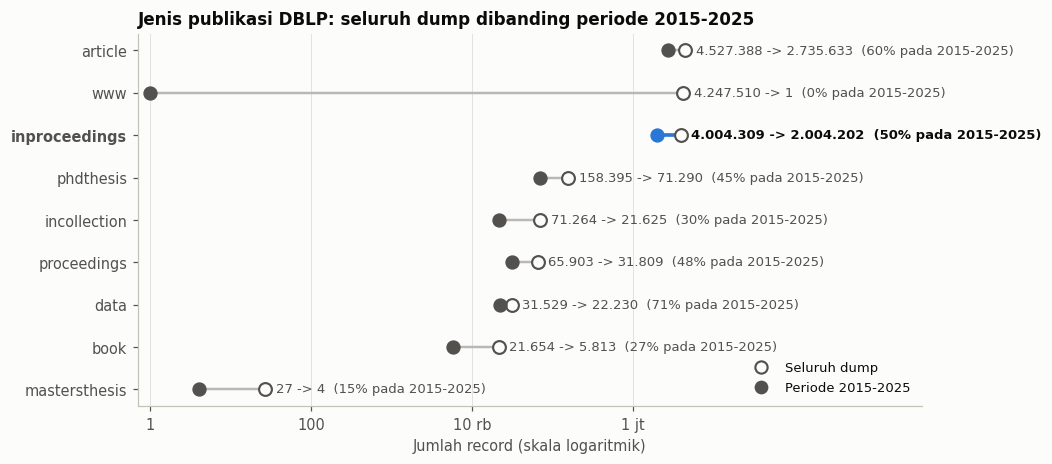

In [10]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
order = types.index[::-1]
for y, name in enumerate(order):
    all_n, per_n = types.loc[name, "seluruh_dblp"], max(types.loc[name, "periode"], 1)
    used = name == "inproceedings"
    ax.plot([per_n, all_n], [y, y], color=CFG.BLUE if used else CFG.GRAY, lw=2.4 if used else 1.6, zorder=1)
    ax.scatter(all_n, y, s=70, facecolor=CFG.SURFACE, edgecolor=CFG.INK_2, lw=1.4, zorder=3)
    ax.scatter(per_n, y, s=70, color=CFG.BLUE if used else CFG.INK_2, zorder=4)
    share = types.loc[name, "porsi_periode_%"]
    ax.text(all_n * 1.35, y, f"{fmt_id(all_n)} -> {fmt_id(types.loc[name, 'periode'])}  ({pct_id(share, 0)} pada 2015-2025)",
            va="center", fontsize=8.6, color=CFG.INK if used else CFG.INK_2, fontweight="bold" if used else "normal")

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.get_yticklabels()[list(order).index("inproceedings")].set_fontweight("bold")
ax.set_xscale("log")
ax.set_xlim(0.7, 4e9)
ax.set_xticks([1, 100, 1e4, 1e6])
ax.set_xticklabels(["1", "100", "10 rb", "1 jt"])
ax.set_xlabel("Jumlah record (skala logaritmik)")
ax.grid(axis="y", visible=False)
ax.set_title("Jenis publikasi DBLP: seluruh dump dibanding periode 2015-2025")
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=CFG.SURFACE, mec=CFG.INK_2, mew=1.4, ms=8, label="Seluruh dump"),
                   Line2D([], [], marker="o", ls="", color=CFG.INK_2, ms=8, label="Periode 2015-2025")],
          loc="lower right", bbox_to_anchor=(1.0, 0.0), fontsize=8.6)
save_fig(fig, "t1_jenis_publikasi.png")

#### Insights

> Dump berisi 13.127.979 record. `article` (4,53 juta) dan `www` (4,25 juta) menyumbang sekitar 67% isi dump, sedangkan `inproceedings` berjumlah 4.004.309 atau sekitar 30,5% dari seluruh record. Dari jumlah itu, 2.004.202 (50,1%) berada pada periode 2015-2025 dan menjadi data mentah tugas ini.

> Jenis `www` hanya memiliki satu record pada 2015-2025. Record ini adalah halaman profil author yang umumnya tidak memiliki tahun, sehingga bukan publikasi dan tidak dipakai. Jenis `proceedings` (65.903 record) adalah buku prosiding induk yang dirujuk oleh `crossref`, bukan paper, sehingga juga tidak dipakai.

> Porsi periode 2015-2025 berbeda antarjenis, dari 26,8% (`book`) sampai 70,5% (`data`). Jenis `inproceedings` berada di tengah, yaitu 50,1%, artinya setengah dari seluruh paper konferensi di DBLP terbit dalam sebelas tahun terakhir.

## 3.3 Atribut dan Kondisi Data Mentah

Tabel mentah diperiksa dari sisi tipe data, nilai kosong, dan komposisi awalan `key`. Pemeriksaan ini menjadi dasar keputusan pada tahap preprocessing.

In [11]:
empty_text = raw.replace("", np.nan)
raw_profile = pd.DataFrame({"tipe_data": raw.dtypes.astype(str)})
raw_profile["kosong"] = empty_text.isna().sum()
raw_profile["kosong_%"] = raw_profile["kosong"] / len(raw) * 100
raw_profile["contoh"] = [empty_text[c].dropna().iloc[0][:45] for c in raw_profile.index]
save_table(raw_profile, "t1_profil_data_mentah.csv")
raw_profile.round(3)

,tipe_data,kosong,kosong_%,contoh
key,object,0,0.000,conf/dac/RoquetSRTSK24
title,object,0,0.000,Cross-Layer Reliability Evaluation and Effici
year,object,0,0.000,2024
booktitle,object,190,0.009,DAC
crossref,object,2471,0.123,conf/dac/2024
authors,object,2255,0.113,Lucas Roquet|Fernando Fernandes dos Santos|Pa


In [12]:
parts = raw["key"].str.split("/")
key_profile = pd.DataFrame({
    "prefiks": parts.str[0].value_counts(),
})
key_profile["%"] = key_profile["prefiks"] / len(raw) * 100
print(f"Key unik: {raw['key'].is_unique} | jumlah segmen: {parts.str.len().value_counts().to_dict()}")
key_profile.round(2)

Key unik: True | jumlah segmen: {3: 2004162, 4: 40}


,prefiks,%
key,,
conf,2001039,99.84
journals,3123,0.16
books,40,0.00


#### Insights

> Dari 2.004.202 record mentah, `title` dan `year` tidak pernah kosong, sedangkan `booktitle` kosong pada 190 record, `crossref` pada 2.471 record, dan `author` pada 2.255 record. Semuanya di bawah 0,13%, sehingga data mentah tergolong bersih dan penanganan nilai kosong berdampak kecil.

> Kolom `year` bertipe teks karena XML tidak memiliki tipe data, sehingga perlu dikonversi menjadi bilangan bulat. Kolom `key` unik pada seluruh baris.

> Sebanyak 99,8% record memiliki `key` berawalan `conf/`. Sisanya (3.163 record) berawalan `journals/` atau `books/`, yaitu record bertag `inproceedings` yang diarsipkan DBLP pada seri jurnal atau buku. Perlakuannya dibahas pada subbagian seleksi konferensi.

---

# Preprocessing (Task 1.2 dan 1.3) <a name="4"></a>

---

Bagian ini menjawab Task 1.2 dan 1.3. Preprocessing dikerjakan pada salinan data mentah dalam enam tahap berurutan. Setiap tahap dibahas dengan pola yang sama, yaitu alasan pemilihan metode, bukti dari data, hasil, lalu insight. Jumlah paper setelah setiap tahap dicatat agar dampaknya dapat ditelusuri.

## 4.1 Rancangan Tahap

Tabel berikut memetakan setiap butir spesifikasi tugas ke tahap preprocessing yang dikerjakan. Urutan tahap sama dengan urutan kode pada subbagian berikutnya.

| # | Tahap | Butir spesifikasi | Perlakuan | Alasan |
|---|---|---|---|---|
| 1 | Konsistensi tahun | Memastikan konsistensi atribut tahun | Konversi teks ke bilangan bulat, lalu validasi rentang 2015-2025 | `year` di XML bertipe teks sehingga tidak dapat dibandingkan atau dihitung |
| 2 | Missing values | Menangani missing values | Buang paper tanpa author; kolom lain dibiarkan | Paper tanpa author tidak dapat masuk transaksi dan umumnya bukan paper |
| 3 | Seleksi konferensi dan workshop | Memilih publikasi konferensi dan workshop | Tag `inproceedings` (saat ekstraksi) dan `key` berawalan `conf/` | Menurut dokumentasi DBLP, `conf/*` adalah paper konferensi atau workshop |
| 4 | Normalisasi venue | Normalisasi nama conference atau venue | Venue diambil dari segmen kedua `key` | `booktitle` tidak konsisten, sedangkan `key` stabil antartahun |
| 5 | Duplikat | Menghilangkan data duplikat | Buang `key` ganda, lalu judul + tahun + venue ganda | Satu paper tidak boleh terhitung dua kali |
| 6 | Normalisasi author | Normalisasi nama author | NFKC dan rapikan spasi; sufiks disambiguasi DBLP dipertahankan; pecah menjadi satu baris per author | Menyeragamkan penulisan tanpa menggabungkan orang yang berbeda |

In [13]:
def norm_text(text):
    if text is None or pd.isna(text):
        return None
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text or None

df = raw.copy()
attrition = [{"tahap": "Data mentah", "paper": len(df), "dibuang": 0}]

def log_step(name, frame):
    attrition.append({"tahap": name, "paper": len(frame), "dibuang": attrition[-1]["paper"] - len(frame)})

## 4.2 Konsistensi Tahun

Kolom `year` dikonversi dari teks menjadi bilangan bulat. Sebelum dikonversi, dicek apakah seluruh nilai berupa empat digit, lalu setelah dikonversi dipastikan semua tahun berada pada rentang analisis.

In [14]:
four_digit = df["year"].str.fullmatch(r"\d{4}")
print(f"Tipe awal       : {df['year'].dtype} | seluruh nilai empat digit: {four_digit.all()}")
print(f"Nilai unik awal : {sorted(df['year'].unique())}")

df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
df = df[df["year"].between(CFG.YEAR_MIN, CFG.YEAR_MAX)]
log_step("Konsistensi tahun", df)

print(f"Tipe akhir      : {df['year'].dtype} | rentang: {df['year'].min()}-{df['year'].max()} | kosong: {df['year'].isna().sum()}")
print(f"Baris dibuang   : {attrition[-1]['dibuang']}")

Tipe awal       : object | seluruh nilai empat digit: True
Nilai unik awal : ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


Tipe akhir      : Int64 | rentang: 2015-2025 | kosong: 0
Baris dibuang   : 0


#### Insights

> Seluruh nilai `year` berupa empat digit dan seluruhnya berada pada 2015-2025, sehingga tidak ada baris yang dibuang. Penyaringan rentang tahun sebenarnya sudah dilakukan saat ekstraksi, jadi tahap ini berfungsi sebagai validasi.

> Konversi tetap diperlukan karena tahun bertipe teks tidak dapat dihitung. Bilangan bulat diperlukan untuk agregasi per tahun, garis tren, dan pembagian periode pada analisis temporal.

## 4.3 Missing Values

Nilai kosong diperiksa pada setiap kolom, lalu keputusan diambil per kolom berdasarkan apakah kolom itu dipakai pada analisis. Kolom `authors` menjadi penentu, karena transaksi dibentuk dari author.

In [15]:
missing_plan = pd.DataFrame({
    "kosong": [(df["authors"] == "").sum(), df["booktitle"].isna().sum(), df["crossref"].isna().sum(),
               df["title"].isna().sum(), df["year"].isna().sum()],
    "keputusan": ["buang baris", "dibiarkan", "dibiarkan", "tidak ada yang kosong", "tidak ada yang kosong"],
    "alasan": ["transaksi dibentuk dari author", "venue diambil dari key, bukan booktitle",
               "crossref tidak dipakai pada analisis", "-", "-"],
}, index=["authors", "booktitle", "crossref", "title", "year"])
missing_plan["kosong_%"] = missing_plan["kosong"] / len(df) * 100
save_table(missing_plan, "t1_missing_values.csv")
missing_plan.round(3)

,kosong,keputusan,alasan,kosong_%
authors,2255,buang baris,transaksi dibentuk dari author,0.113
booktitle,190,dibiarkan,"venue diambil dari key, bukan booktitle",0.009
crossref,2471,dibiarkan,crossref tidak dipakai pada analisis,0.123
title,0,tidak ada yang kosong,-,0.000
year,0,tidak ada yang kosong,-,0.000


Judul pada record tanpa author diperiksa untuk memastikan record tersebut memang bukan paper, lalu salah satu record contoh ditampilkan apa adanya dari dump.

In [16]:
no_author = df[df["authors"] == ""]
print("Judul paling sering pada record tanpa author:")
print(no_author["title"].value_counts().head(6).to_string())
print()
print(dump_info["sample_records"]["conf/dac/X22"])

Judul paling sering pada record tanpa author:
title
Front Matter, Table of Contents, Preface, Conference Organization.    349
Preface.                                                              143
Frontmatter.                                                          128
Conference Overview and Papers Program.                                36
Front Matter.                                                          31
Introduction.                                                           6

<inproceedings mdate="2022-08-25" key="conf/dac/X22">
<title>Frontmatter.</title>
<year>2022</year>
<booktitle>DAC</booktitle>
<ee>https://dl.acm.org/action/showFmPdf?doi=10.1145%2F3489517</ee>
<crossref>conf/dac/2022</crossref>
<url>db/conf/dac/dac2022.html#X22</url>
</inproceedings>


In [17]:
df = df[df["authors"] != ""]
log_step("Missing value (tanpa author)", df)
print(f"Baris dibuang: {attrition[-1]['dibuang']:,} | sisa: {len(df):,}")

Baris dibuang: 2,255 | sisa: 2,001,947


#### Insights

> Hanya 2.255 record (0,11%) yang tidak memiliki author. Judulnya menunjukkan bahwa record tersebut bukan paper, melainkan halaman depan prosiding seperti "Front Matter, Table of Contents, Preface, Conference Organization." dan "Preface.". Karena itu membuang record ini sekaligus membersihkan non-paper dari dataset.

> Kolom `booktitle` (190 kosong) dan `crossref` (2.471 kosong) dibiarkan karena tidak dipakai: venue diturunkan dari `key`, bukan dari `booktitle`. Kolom `title` dan `year` tidak memiliki nilai kosong.

## 4.4 Seleksi Konferensi dan Workshop

Konferensi dan workshop pada DBLP sama-sama bertag `inproceedings`, sehingga tidak ada tag yang memisahkan keduanya. Tag itu sudah dipilih saat ekstraksi. Tahap ini menambah satu syarat, yaitu `key` berawalan `conf/`, yang menurut dokumentasi DBLP adalah tempat paper konferensi dan workshop. Record bertag `inproceedings` yang berawalan lain diperiksa dahulu sebelum dibuang.

In [18]:
prefix = df["key"].str.split("/").str[:2].str.join("/")
non_conf = df[~df["key"].str.startswith("conf/")]

non_conf_profile = (
    non_conf.assign(awalan=prefix[non_conf.index])
    .groupby("awalan")
    .agg(paper=("key", "size"), acara_berbeda=("booktitle", "nunique"),
         acara_terbesar=("booktitle", lambda s: s.value_counts().max()))
    .sort_values("paper", ascending=False)
)
save_table(non_conf_profile, "t1_record_non_conf.csv")
print(f"Record bertag inproceedings tetapi key bukan conf/: {len(non_conf):,} ({len(non_conf) / len(df):.2%})")
print("Acara terbanyak:", non_conf["booktitle"].value_counts().head(5).to_dict())
non_conf_profile

Record bertag inproceedings tetapi key bukan conf/: 3,161 (0.16%)
Acara terbanyak: {'MFPS': 187, 'QPL': 183, 'GandALF': 165, 'TARK': 160, 'ACT': 131}


,paper,acara_berbeda,acara_terbesar
awalan,,,
journals/corr,2734,130,183
journals/entcs,387,16,94
books/sp,40,2,27


Tag dan awalan `key` tidak selalu sejalan. Record contoh berikut bertag `article` tetapi berawalan `conf/`, karena tag mengikuti jenis publikasi (jurnal RLJ) sedangkan `key` mengikuti seri venue. Karena hanya tag `inproceedings` yang diambil, record seperti ini otomatis tidak ikut.

In [19]:
for line in dump_info["sample_records"]["conf/rlc/IshfaqT0LLMP024"].splitlines():
    if line.startswith(("<article", "<journal", "<title")):
        print(line[:120])

<article mdate="2026-02-16" key="conf/rlc/IshfaqT0LLMP024">
<title>More Efficient Randomized Exploration for Reinforcement Learning via Approximate Sampling.</title>
<journal>RLJ</journal>


In [20]:
df = df[df["key"].str.startswith("conf/")].copy()
log_step("Seleksi konferensi (key conf/)", df)
print(f"Baris dibuang: {attrition[-1]['dibuang']:,} | sisa: {len(df):,}")

Baris dibuang: 3,161 | sisa: 1,998,786


#### Insights

> Sebanyak 3.161 record (0,16%) bertag `inproceedings` tetapi tidak berawalan `conf/`. Rinciannya 2.734 record berawalan `journals/corr`, 387 berawalan `journals/entcs`, dan 40 berawalan `books/sp`. Record ini adalah prosiding acara kecil yang diarsipkan DBLP pada seri jurnal atau buku.

> Record tersebut tersebar pada sekitar 150 acara berbeda (130 pada `journals/corr`, 16 pada `journals/entcs`, dan 2 pada `books/sp`), dan acara terbesarnya hanya 187 paper (MFPS). Angka itu jauh di bawah ambang min support terendah, karena 0,1% dari 1,82 juta author adalah sekitar 1.800 author. Selain itu, `key` mereka akan menyatukan 130 acara berbeda ke dalam satu venue palsu `corr`. Karena itu record ini dibuang.

> Keputusan ini perlu dicatat sebagai keterbatasan: sebagian record yang dibuang memang prosiding konferensi atau workshop kecil, sehingga ada sedikit workshop yang tidak terambil. Dampaknya pada hasil mining diperkirakan tidak ada.

## 4.5 Normalisasi Venue

Spesifikasi meminta nama conference atau venue dinormalisasi. Elemen `booktitle` adalah kandidat yang jelas, tetapi nilainya ditulis berbeda antartahun dan antartrack. Segmen kedua `key` (`conf/kdd/ChenG16` menjadi `kdd`) menyatakan seri konferensi yang sama sepanjang waktu, sehingga dipilih sebagai venue. Perbandingan keduanya ditunjukkan di bawah.

In [21]:
df["venue"] = df["key"].str.split("/").str[1]

bt = df["booktitle"].fillna("(kosong)")
size = df.groupby("venue").size()
variants = bt.groupby(df["venue"]).nunique()
dominant_name = bt.groupby(df["venue"]).agg(lambda s: s.value_counts().index[0])
is_dominant = pd.Series(bt.values == dominant_name.reindex(df["venue"]).values, index=df.index)
off_name = size - is_dominant.groupby(df["venue"]).sum()

venue_norm = pd.Series({
    "nama booktitle berbeda": df["booktitle"].nunique(),
    "venue (segmen kedua key)": df["venue"].nunique(),
    "venue yang memiliki lebih dari satu variasi booktitle": int((variants > 1).sum()),
    "paper dengan booktitle bukan nama dominan venue-nya": int(off_name.sum()),
}, name="jumlah").to_frame()
venue_norm["%"] = [np.nan, np.nan, venue_norm.iloc[2, 0] / df["venue"].nunique() * 100, venue_norm.iloc[3, 0] / len(df) * 100]
save_table(venue_norm, "t1_normalisasi_venue.csv")
venue_norm.round(1)

,jumlah,%
nama booktitle berbeda,8784,NaN
venue (segmen kedua key),4373,NaN
venue yang memiliki lebih dari satu variasi booktitle,1270,29.0
paper dengan booktitle bukan nama dominan venue-nya,377262,18.9


Perbedaan itu divisualisasikan sebagai stacked column per tahun, yaitu varian chart komposisi dalam panduan Datawrapper yang cocok untuk melihat pergeseran nama dari waktu ke waktu. Tiga venue dipilih karena masing-masing mewakili satu jenis masalah: pergantian nama (`nips`), workshop di bawah konferensi induk (`cvpr`), dan track tambahan (`chi`).

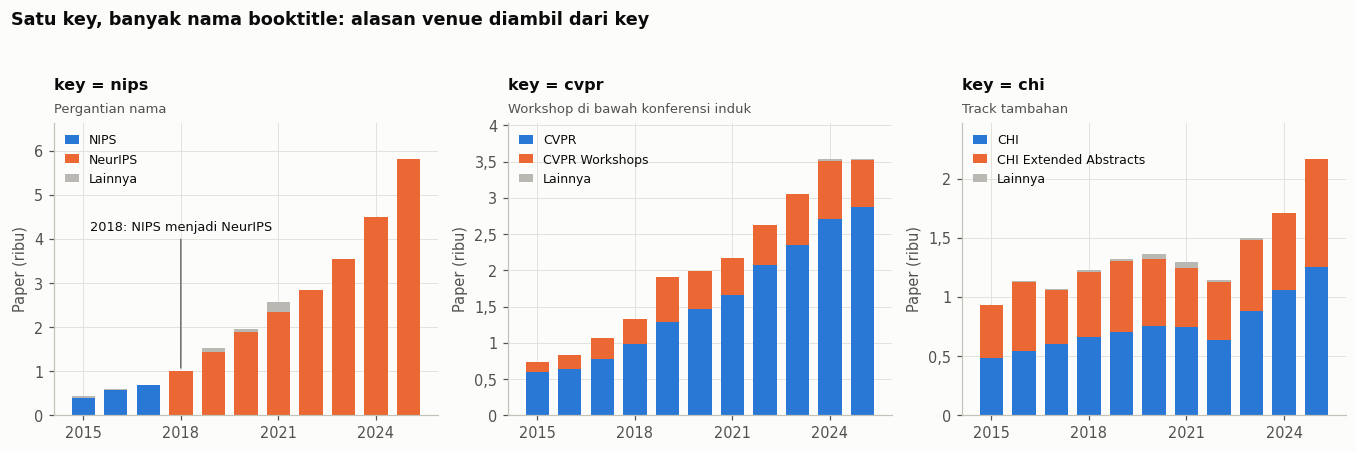

In [22]:
panels = [
    ("nips", ["NIPS", "NeurIPS"], "Pergantian nama"),
    ("cvpr", ["CVPR", "CVPR Workshops"], "Workshop di bawah konferensi induk"),
    ("chi", ["CHI", "CHI Extended Abstracts"], "Track tambahan"),
]
colors = [CFG.BLUE, CFG.ORANGE]

fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.9))
for ax, (venue, names, subtitle) in zip(axes, panels):
    sub = df[df["venue"] == venue]
    grouped = sub["booktitle"].fillna("(kosong)").where(lambda s: s.isin(names), "Lainnya")
    table = pd.crosstab(sub["year"].astype(int), grouped).reindex(columns=names + ["Lainnya"], fill_value=0)
    bottom = np.zeros(len(table))
    for column, color in zip(table.columns, colors + [CFG.GRAY]):
        if table[column].sum() == 0:
            continue
        ax.bar(table.index, table[column] / 1e3, bottom=bottom, color=color, width=0.72, label=column, zorder=2)
        bottom += table[column].values / 1e3
    ax.set_title(f"key = {venue}", fontsize=10.5, pad=22)
    ax.text(0, 1.035, subtitle, transform=ax.transAxes, fontsize=8.6, color=CFG.INK_2)
    ax.set_xticks([2015, 2018, 2021, 2024])
    ax.set_ylim(0, bottom.max() * 1.14)
    ax.set_ylabel("Paper (ribu)")
    id_ticks(ax)
    ax.legend(loc="upper left", fontsize=8.2, handlelength=1.1)
axes[0].annotate("2018: NIPS menjadi NeurIPS", xy=(2018, 1.0), xytext=(2015.2, 4.2),
                 fontsize=8.4, color=CFG.INK, arrowprops=dict(arrowstyle="-", color=CFG.INK_2, lw=0.8))
fig.suptitle("Satu key, banyak nama booktitle: alasan venue diambil dari key", x=0.01, ha="left", fontweight="bold", fontsize=11.5, y=1.04)
fig.tight_layout()
save_fig(fig, "t1_normalisasi_venue.png")

Nama tampilan setiap venue untuk grafik dan tabel berikutnya diambil dari `booktitle` yang paling sering dipakai venue tersebut, setelah menghapus keterangan dalam kurung dan akhiran seperti `Workshops`. Jika beberapa venue mendapat nama yang sama, venue terbesar memakai nama polos dan venue lainnya diberi kunci venue dalam kurung siku agar tetap dapat dibedakan.

In [23]:
def clean_booktitle(text):
    text = re.sub(r"\s*\(.*?\)\s*$", "", str(text))
    text = re.sub(r"\s+(Workshops?|Extended Abstracts)$", "", text)
    return text.strip()

venue_label = dominant_name.map(clean_booktitle)
largest_for_label = size.groupby(venue_label).idxmax()

def display_name(venue):
    label = venue_label[venue]
    return label if largest_for_label[label] == venue else f"{label} [{venue}]"

venue_label.rename("nama_tampil").rename_axis("venue").to_frame().to_csv(CFG.PROC_DIR / "venue_label.csv")

pd.DataFrame({"venue": ["nips", "hci", "acl", "amcc", "vtc"],
              "nama_tampil": [display_name(v) for v in ["nips", "hci", "acl", "amcc", "vtc"]]})

,venue,nama_tampil
0,nips,NeurIPS
1,hci,HCI
2,acl,ACL
3,amcc,ACC
4,vtc,VTC Fall


#### Insights

> `booktitle` memiliki 8.784 nama berbeda, sedangkan `key` hanya menghasilkan 4.373 venue. Sebanyak 1.270 venue (29%) memiliki lebih dari satu variasi `booktitle`, dan 377.262 paper (18,9%) memakai `booktitle` yang bukan nama utama venue-nya. Memakai `booktitle` akan memecah satu konferensi menjadi beberapa venue.

> Contoh paling jelas adalah NeurIPS: `booktitle` tercatat `NIPS` pada 2015-2017 dan `NeurIPS` sejak 2018, padahal `key` tetap `nips`. Pada CVPR dan CHI, `booktitle` juga memisahkan acara utama dari workshop dan extended abstracts.

> Pemakaian `key` memiliki konsekuensi: workshop dan track tambahan ikut terhitung sebagai konferensi induknya. Pada CVPR, workshop menyumbang sekitar 23% paper, dan pada CHI sekitar 44%. Hal ini dicatat sebagai asumsi dan keterbatasan, terutama untuk peringkat popularitas pada Task 2.

## 4.6 Duplikat

Duplikat dicari dalam dua lapis. Lapis pertama adalah `key` ganda, yang seharusnya tidak ada karena `key` dijamin unik. Lapis kedua adalah paper dengan judul, tahun, dan venue yang sama tetapi `key` berbeda. Judul dinormalisasi lebih dahulu (huruf kecil, spasi dirapikan, titik akhir dibuang) agar perbedaan penulisan kecil tidak menyembunyikan duplikat.

In [24]:
df["title_norm"] = df["title"].map(norm_text).str.lower().str.rstrip(".")
dup_keys = ["title_norm", "year", "venue"]

print(f"Key ganda: {df['key'].duplicated().sum()}")
print(f"Jika daftar author ikut menjadi kunci duplikat, baris yang dibuang: {df.duplicated(dup_keys + ['authors']).sum():,}")

groups = (df[df.duplicated(dup_keys, keep=False)]
          .groupby(dup_keys)
          .agg(baris=("key", "size"), daftar_author=("authors", "nunique")))
groups["dibuang"] = groups["baris"] - 1
same_authors = groups["daftar_author"] == 1

dup_summary = pd.DataFrame({
    "grup": [len(groups), same_authors.sum(), (~same_authors).sum()],
    "baris_dibuang": [groups["dibuang"].sum(), groups.loc[same_authors, "dibuang"].sum(), groups.loc[~same_authors, "dibuang"].sum()],
}, index=["Semua grup judul + tahun + venue ganda", "Daftar author identik", "Daftar author berbeda"])
dup_summary["grup_%"] = dup_summary["grup"] / len(groups) * 100
save_table(dup_summary, "t1_duplikat.csv")
dup_summary.round(1)

Key ganda: 0


Jika daftar author ikut menjadi kunci duplikat, baris yang dibuang: 1,127


,grup,baris_dibuang,grup_%
Semua grup judul + tahun + venue ganda,1373,1542,100.0
Daftar author identik,1100,1121,80.1
Daftar author berbeda,273,421,19.9


Grup dengan daftar author berbeda diperiksa secara khusus, karena di situlah aturan ini berpotensi menghapus paper yang sebenarnya berbeda. Contoh dan judul yang paling sering muncul ditampilkan berikut.

In [25]:
different = groups[~same_authors].reset_index()

for _, row in different.head(5).iterrows():
    members = df[(df["title_norm"] == row["title_norm"]) & (df["year"] == row["year"]) & (df["venue"] == row["venue"])]
    print(f"[{row['venue']} {row['year']}] {row['title_norm'][:62]}")
    for _, member in members.iterrows():
        print("   ", member["key"], "|", member["authors"][:68])

print()
print("Judul yang paling sering pada grup author berbeda:")
print(different["title_norm"].value_counts().head(6).to_string())

[fgr 2015] 3d interaction design: increasing the stimulus-response corres
    conf/fgr/FetzerPDH15 | Toni Fetzer|Christian Petry|Frank Deinzer|Karsten Huffstadt
    conf/fgr/FetzerP15 | Toni Fetzer|Christian Petry
[vlsi 2020] 3d logic cells design and results based on vertical nwfet tech
    conf/vlsi/PoittevinMOMLDB20 | Arnaud Poittevin|Chhandak Mukherjee|Ian O'Connor|Cristell Maneux|Gui
    conf/vlsi/MukherjeeDMMPOB20 | Chhandak Mukherjee|Marina Deng|François Marc|Cristell Maneux|Arnaud 
[chi 2015] a dose of reality: overcoming usability challenges in vr head-
    conf/chi/McGillBMB15 | Mark McGill|Daniel Boland|Roderick Murray-Smith|Stephen A. Brewster
    conf/chi/McGillMBB15 | Mark McGill|Roderick Murray-Smith|Daniel Boland|Stephen A. Brewster


[tabletop 2016] a dynamic 3d performance space for control of virtual musical 
    conf/tabletop/HollenbachCG16 | Andrew Hollenbach|Matthew Cox|Joe Geigel
    conf/tabletop/CoxHG16 | Matthew Cox|Andrew Hollenbach|Joe Geigel
[simpda 2017] a linear temporal logic model checking method over finite word
    conf/simpda/CouvreurE17 | Jean-Michel Couvreur|Joaquin Ezpeleta
    conf/simpda/CouvreurE17a | Jean-Michel Couvreur|Joaquín Ezpeleta

Judul yang paling sering pada grup author berbeda:
title_norm
preface                                                 27
vorwort                                                  6
session introduction                                     6
session details: keynote address                         5
summary report                                           2
proceedings in adaptation, learning and optimization     2


In [26]:
df = df.drop_duplicates("key")
df = df[~df.duplicated(dup_keys)]
log_step("Duplikat (key, judul + tahun + venue)", df)
print(f"Baris dibuang: {attrition[-1]['dibuang']:,} | sisa: {len(df):,}")

Baris dibuang: 1,542 | sisa: 1,997,244


#### Insights

> Tidak ada `key` ganda, tetapi ada 1.373 grup paper dengan judul, tahun, dan venue yang sama sehingga 1.542 baris dibuang (0,08% data). Seluruh anggota grup memiliki `key` berbeda, biasanya dengan akhiran huruf seperti `...23` dan `...23a`.

> Sebanyak 80% grup memiliki daftar author yang identik, jadi hampir pasti duplikat. Sekitar 20% grup memiliki daftar author berbeda. Contohnya adalah paper yang sama dengan urutan author berbeda, ejaan nama berbeda (`Joaquin` dan `Joaquín`), atau subset author. Sebagian lain adalah judul generik seperti "Preface", "Vorwort", dan "Session introduction" yang memang dokumen berbeda tetapi bukan paper penelitian.

> Aturan dipertahankan karena dampaknya sangat kecil dan hasil keduanya hampir sama: jika daftar author ikut menjadi kunci, yang dibuang 1.127 baris, sehingga hanya sekitar 415 baris yang berbeda. Risikonya (menghapus paper yang berbeda) dicatat sebagai keterbatasan.

## 4.7 Normalisasi Author

Nama author dinormalisasi dengan NFKC (menyeragamkan karakter yang setara secara Unicode) dan perapian spasi, lalu setiap paper dipecah menjadi satu baris per author. Sufiks angka seperti `Tianqi Chen 0001` sengaja dipertahankan karena sufiks itu adalah penanda dari DBLP bahwa dua orang berbeda memiliki nama yang sama. Menghapusnya justru akan menggabungkan orang yang berbeda. Efek normalisasi diukur, bukan diasumsikan.

In [27]:
pairs = (df[["key", "year", "venue", "authors"]]
         .assign(author_raw=df["authors"].str.split("|"))
         .explode("author_raw")
         .drop(columns="authors")
         .reset_index(drop=True))

unique_names = pairs["author_raw"].drop_duplicates()
mapping = dict(zip(unique_names, unique_names.map(norm_text)))
pairs["author"] = pairs["author_raw"].map(mapping)

author_norm = pd.Series({
    "pasangan paper-author sebelum": len(pairs),
    "nama author unik sebelum normalisasi": unique_names.nunique(),
    "nama author unik sesudah normalisasi": pairs["author"].nunique(),
    "nama yang berubah karena NFKC atau spasi": int((pairs["author"] != pairs["author_raw"]).sum()),
}, name="jumlah").to_frame()
author_norm

,jumlah
pasangan paper-author sebelum,7870999
nama author unik sebelum normalisasi,1821757
nama author unik sesudah normalisasi,1821757
nama yang berubah karena NFKC atau spasi,0


Karena NFKC dan spasi ternyata tidak mengubah satu nama pun, diperiksa pula seberapa banyak nama yang berbeda hanya pada huruf besar-kecil atau tanda diakritik (misalnya `A. Gómez` dan `A. Gomez`). Pemeriksaan ini hanya mengukur, tidak menggabungkan, karena nama yang tampak serupa belum tentu orang yang sama.

In [28]:
def fold_name(name):
    lowered = unicodedata.normalize("NFKD", name.casefold())
    return "".join(c for c in lowered if not unicodedata.combining(c))

folded = unique_names.map(fold_name)
members = pd.DataFrame({"nama": unique_names.values, "lipat": folded.values})
collision = members.groupby("lipat")["nama"].nunique()
collision = collision[collision > 1]

print(f"Kelompok nama yang bentrok jika huruf besar-kecil dan diakritik dilipat: {len(collision):,} "
      f"({len(collision) / unique_names.nunique():.2%} dari nama unik)")
print("Contoh:")
print(members[members["lipat"].isin(collision.index[:6])].groupby("lipat")["nama"].apply(list).to_string())

Kelompok nama yang bentrok jika huruf besar-kecil dan diakritik dilipat: 7,573 (0.42% dari nama unik)
Contoh:
lipat
a. gomez                                        [Á. Gómez, A. Gómez]
a. gonzalez                               [A. González, A. Gonzalez]
a. j. ustariz-farfan    [A. J. Ustariz-Farfan, A. J. Ustariz-Farfán]
a. martinez                               [A. Martinez, A. Martínez]
a. murat ozbayoglu          [A. Murat Ozbayoglu, A. Murat Özbayoglu]
a. rodriguez                            [A. Rodríguez, A. Rodriguez]


In [29]:
paper_author = (pairs.dropna(subset=["author"])
                .drop_duplicates(["key", "author"])[["key", "year", "venue", "author"]]
                .reset_index(drop=True))

has_suffix = paper_author["author"].str.contains(r" \d{4}$")
venues_per_author = paper_author.groupby("author")["venue"].nunique().sort_values(ascending=False)

author_extra = pd.Series({
    "pasangan paper-author ganda dalam satu paper (dibuang)": len(pairs) - len(paper_author),
    "pasangan paper-author akhir": len(paper_author),
    "nama dengan sufiks disambiguasi DBLP": paper_author.loc[has_suffix, "author"].nunique(),
}, name="jumlah").to_frame()
display(author_extra)
print("Author dengan venue terbanyak (calon nama gabungan banyak orang):")
print(venues_per_author.head(5).to_string())

,jumlah
pasangan paper-author ganda dalam satu paper (dibuang),97
pasangan paper-author akhir,7870902
nama dengan sufiks disambiguasi DBLP,90593


Author dengan venue terbanyak (calon nama gabungan banyak orang):
author
Yang Liu    332
Wei Wang    280
Lei Wang    262
Xin Wang    255
Hao Wang    254


#### Insights

> Normalisasi Unicode dan spasi tidak mengubah satu pun dari 7,87 juta kemunculan nama author (1,82 juta nama unik), sehingga DBLP sudah menyajikan nama dalam bentuk yang bersih. Tahap ini tetap dijalankan sebagai pengaman, dan hasil nolnya adalah temuan yang perlu dilaporkan apa adanya.

> Sebanyak 97 pasangan paper-author ganda dalam satu paper dibuang, dan 90.593 nama membawa sufiks disambiguasi DBLP yang dipertahankan. Hasil akhirnya adalah 7.870.902 pasangan paper-author.

> Ada 7.573 kelompok nama (0,4% dari nama unik) yang hanya berbeda huruf besar-kecil atau diakritik, misalnya `A. Gómez` dan `A. Gomez`. Nama-nama ini tidak digabung karena sebagian besar berupa inisial yang sudah ambigu, dan penggabungan berisiko menyatukan orang yang berbeda. Dampaknya kecil dan dicatat sebagai keterbatasan.

> Masalah sebaliknya lebih berpengaruh: nama umum tanpa sufiks dapat mewakili banyak orang sekaligus. `Yang Liu` tercatat pada 332 venue dan `Wei Wang` pada 280 venue, sehingga transaksi untuk nama-nama ini bukan riwayat satu orang. Hal ini menjadi keterbatasan utama pada analisis berbasis author.

## 4.8 Hasil Preprocessing dan Penyimpanan

Ringkasan jumlah paper setelah setiap tahap disusun dalam satu tabel, lalu divisualisasikan sebagai lollipop chart untuk membandingkan besar pengurangan antartahap. Tabel dan grafik ini menjawab Task 1.3, yaitu seberapa besar dampak setiap tahap.

In [30]:
attrition_df = pd.DataFrame(attrition)
raw_total = attrition_df["paper"].iloc[0]
attrition_df["dibuang_%_dari_mentah"] = attrition_df["dibuang"] / raw_total * 100
attrition_df["retensi_%"] = attrition_df["paper"] / raw_total * 100
save_table(attrition_df, "t1_ringkasan_preprocessing.csv", index=False)
attrition_df.round(3)

,tahap,paper,dibuang,dibuang_%_dari_mentah,retensi_%
0,Data mentah,2004202,0,0.000,100.000
1,Konsistensi tahun,2004202,0,0.000,100.000
2,Missing value (tanpa author),2001947,2255,0.113,99.887
3,Seleksi konferensi (key conf/),1998786,3161,0.158,99.730
4,"Duplikat (key, judul + tahun + venue)",1997244,1542,0.077,99.653


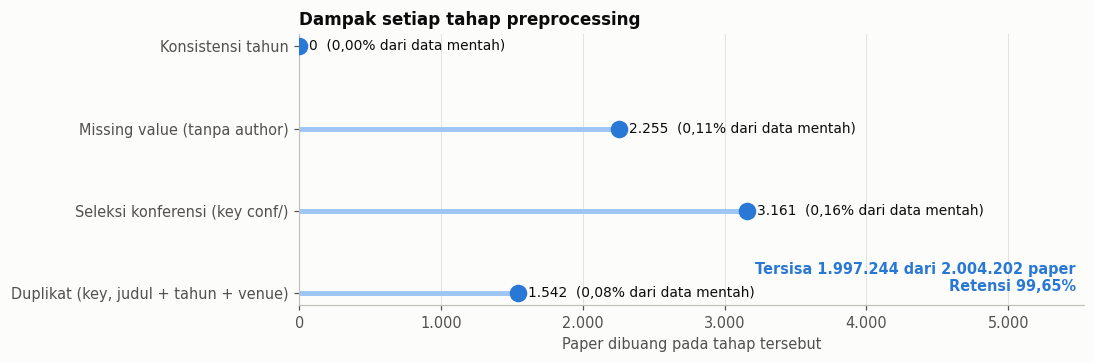

In [31]:
steps = attrition_df.iloc[1:].reset_index(drop=True)
final_paper = attrition_df["paper"].iloc[-1]

fig, ax = plt.subplots(figsize=(9.2, 3.2))
y = np.arange(len(steps))[::-1]
ax.hlines(y, 0, steps["dibuang"], color=CFG.BLUE_LIGHT, lw=3.2, zorder=1)
ax.scatter(steps["dibuang"], y, s=110, color=CFG.BLUE, zorder=3)
for yi, (_, row) in zip(y, steps.iterrows()):
    ax.text(row["dibuang"] + 70, yi, f"{fmt_id(row['dibuang'])}  ({pct_id(row['dibuang_%_dari_mentah'], 2)} dari data mentah)",
            va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(steps["tahap"])
ax.set_xlim(0, steps["dibuang"].max() * 1.75)
ax.set_xlabel("Paper dibuang pada tahap tersebut")
id_ticks(ax, "x")
ax.grid(axis="y", visible=False)
ax.set_title("Dampak setiap tahap preprocessing")
ax.text(0.99, 0.04, f"Tersisa {fmt_id(final_paper)} dari {fmt_id(raw_total)} paper\nRetensi {pct_id(final_paper / raw_total * 100, 2)}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5, fontweight="bold", color=CFG.BLUE)
save_fig(fig, "t1_dampak_preprocessing.png")

Alur seleksi dari seluruh dump sampai dataset bersih digambarkan sebagai sankey diagram, jenis chart yang dalam panduan Datawrapper dipakai untuk menunjukkan aliran dalam sebuah sistem. Ketebalan pita sebanding dengan jumlah record. Aliran yang sangat kecil digambar dengan ketebalan minimum agar tetap terlihat.

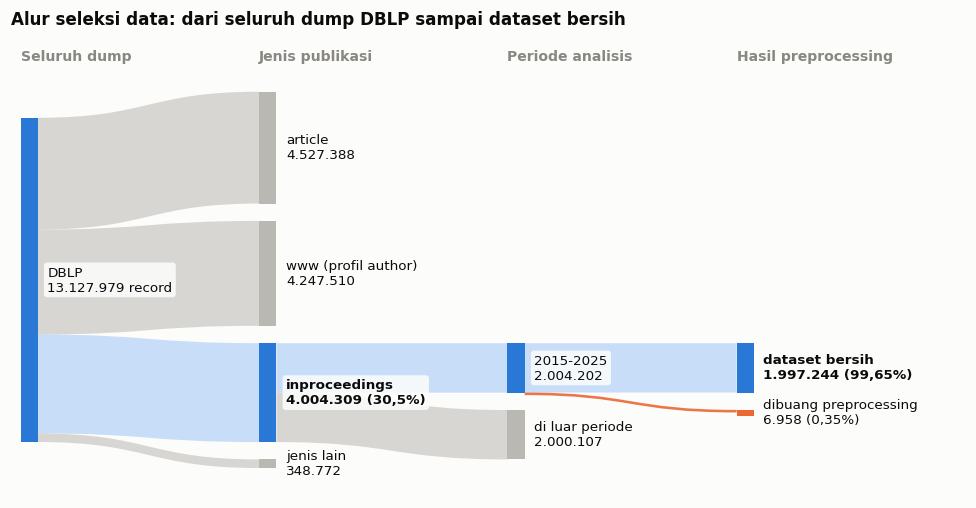

In [32]:
n_total = int(record_types["seluruh_dblp"].sum())
n_article = int(record_types.loc["article", "seluruh_dblp"])
n_www = int(record_types.loc["www", "seluruh_dblp"])
n_inproc = int(record_types.loc["inproceedings", "seluruh_dblp"])
n_period = int(record_types.loc["inproceedings", "periode"])
n_other = n_total - n_article - n_www - n_inproc
n_clean = int(final_paper)
n_removed = n_period - n_clean

values = {"article": n_article, "www": n_www, "inproc": n_inproc, "other": n_other,
          "period": n_period, "outside": n_inproc - n_period, "clean": n_clean, "removed": n_removed}
scale = 56 / n_total
min_node, min_flow, gap, node_w = 1.0, 0.45, 3.0, 1.8

height = {k: max(v * scale, min_node) for k, v in values.items()}
height["dblp"] = height["article"] + height["www"] + height["inproc"] + height["other"]

top = 12
pos = {"article": (26, top)}
pos["www"] = (26, pos["article"][1] + height["article"] + gap)
pos["inproc"] = (26, pos["www"][1] + height["www"] + gap)
pos["other"] = (26, pos["inproc"][1] + height["inproc"] + gap)
pos["dblp"] = (1, top + (pos["other"][1] + height["other"] - top - height["dblp"]) / 2)
pos["period"] = (52, pos["inproc"][1])
pos["outside"] = (52, pos["period"][1] + height["period"] + gap)
pos["clean"] = (76, pos["period"][1])
pos["removed"] = (76, pos["clean"][1] + height["clean"] + gap)

used, muted, flagged = CFG.BLUE, CFG.GRAY, CFG.ORANGE
node_color = {"dblp": used, "article": muted, "www": muted, "inproc": used, "other": muted,
              "period": used, "outside": muted, "clean": used, "removed": flagged}
links = [("dblp", "article", used), ("dblp", "www", used), ("dblp", "inproc", used), ("dblp", "other", used),
         ("inproc", "period", used), ("inproc", "outside", used), ("period", "clean", used), ("period", "removed", used)]
link_value = {("dblp", "article"): n_article, ("dblp", "www"): n_www, ("dblp", "inproc"): n_inproc,
              ("dblp", "other"): n_other, ("inproc", "period"): n_period, ("inproc", "outside"): n_inproc - n_period,
              ("period", "clean"): n_clean, ("period", "removed"): n_removed}

labels = {
    "dblp": f"DBLP\n{fmt_id(n_total)} record",
    "article": f"article\n{fmt_id(n_article)}",
    "www": f"www (profil author)\n{fmt_id(n_www)}",
    "inproc": f"inproceedings\n{fmt_id(n_inproc)} ({pct_id(n_inproc / n_total * 100)})",
    "other": f"jenis lain\n{fmt_id(n_other)}",
    "period": f"2015-2025\n{fmt_id(n_period)}",
    "outside": f"di luar periode\n{fmt_id(n_inproc - n_period)}",
    "clean": f"dataset bersih\n{fmt_id(n_clean)} ({pct_id(n_clean / n_period * 100, 2)})",
    "removed": f"dibuang preprocessing\n{fmt_id(n_removed)} ({pct_id(n_removed / n_period * 100, 2)})",
}

fig, ax = plt.subplots(figsize=(11.2, 5.4))
out_offset = {k: 0.0 for k in pos}
in_offset = {k: 0.0 for k in pos}
for src_id, dst_id, color in links:
    thickness = max(link_value[(src_id, dst_id)] * scale, min_flow)
    x0, y0 = pos[src_id][0] + node_w, pos[src_id][1] + out_offset[src_id]
    x1, y1 = pos[dst_id][0], pos[dst_id][1] + in_offset[dst_id]
    out_offset[src_id] += thickness
    in_offset[dst_id] += thickness
    xm = (x0 + x1) / 2
    verts = [(x0, y0), (xm, y0), (xm, y1), (x1, y1), (x1, y1 + thickness), (xm, y1 + thickness),
             (xm, y0 + thickness), (x0, y0 + thickness), (x0, y0)]
    codes = [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.LINETO,
             MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.CLOSEPOLY]
    ribbon_color = flagged if dst_id == "removed" else (CFG.BLUE_LIGHT if dst_id in ("inproc", "period", "clean") or src_id == "dblp" and dst_id == "inproc" else CFG.GRAY)
    ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=ribbon_color, edgecolor="none",
                           alpha=0.9 if dst_id == "removed" else 0.55, zorder=1))

for node_id, (x, y_top) in pos.items():
    ax.add_patch(Rectangle((x, y_top), node_w, height[node_id], facecolor=node_color[node_id], edgecolor="none", zorder=3))
    ax.text(x + node_w + 1.0, y_top + height[node_id] / 2, labels[node_id], va="center", ha="left", fontsize=8.8, zorder=4,
            fontweight="bold" if node_id in ("inproc", "clean") else "normal",
            bbox=dict(boxstyle="round,pad=0.25", fc=CFG.SURFACE, ec="none", alpha=0.88))

for x, text in [(1, "Seluruh dump"), (26, "Jenis publikasi"), (52, "Periode analisis"), (76, "Hasil preprocessing")]:
    ax.text(x, 6.5, text, fontsize=9.2, color=CFG.MUTED, fontweight="bold")

ax.set_xlim(0, 100)
ax.set_ylim(82, 3)
ax.axis("off")
ax.set_title("Alur seleksi data: dari seluruh dump DBLP sampai dataset bersih", pad=10)
save_fig(fig, "t1_alur_seleksi.png")

Hasil preprocessing disimpan ke disk dalam dua tabel. Tabel paper (`inproceedings_clean`) dipakai untuk menghitung hal per paper, dan tabel pasangan paper-author (`paper_author`) dipakai untuk menghitung hal per author serta membentuk transaksi. Tabel besar di memori dilepas setelah disimpan, dan bagian berikutnya membaca ulang hanya kolom yang dibutuhkan.

In [33]:
df.drop(columns=["title_norm"]).to_parquet(CFG.CLEAN_PARQUET, index=False)
paper_author.to_parquet(CFG.PAPER_AUTHOR_PARQUET, index=False)

print(f"inproceedings_clean.parquet : {len(df):,} paper    ({CFG.CLEAN_PARQUET.stat().st_size / 1e6:,.0f} MB)")
print(f"paper_author.parquet        : {len(paper_author):,} pasangan ({CFG.PAPER_AUTHOR_PARQUET.stat().st_size / 1e6:,.0f} MB)")

del raw, df, pairs, paper_author

inproceedings_clean.parquet : 1,997,244 paper    (211 MB)
paper_author.parquet        : 7,870,902 pasangan (132 MB)


#### Insights

> Preprocessing hanya membuang 6.958 dari 2.004.202 paper, sehingga retensi data 99,65%. Rinciannya: 3.161 paper bukan berawalan `conf/` (45%), 2.255 tanpa author (32%), dan 1.542 duplikat (22%). Tahap konsistensi tahun tidak membuang apa pun.

> Sankey diagram menunjukkan bahwa penyempitan terbesar justru terjadi sebelum preprocessing, yaitu saat memilih `inproceedings` (30,5% dari seluruh dump) dan periode 2015-2025 (separuhnya). Preprocessing sendiri hanya membersihkan sisa kecil, sehingga hasil analisis hampir sepenuhnya ditentukan oleh aturan seleksi pada tahap ekstraksi.

> Hasil akhirnya adalah 1.997.244 paper dan 7.870.902 pasangan paper-author. Kedua tabel disimpan dan menjadi masukan bagi seluruh task berikutnya.

---

# Statistik Dataset Bersih (Task 1.4) <a name="5"></a>

---

Bagian ini menjawab Task 1.4. Seluruh angka dihitung dari parquet hasil preprocessing, dan hanya kolom yang dibutuhkan yang dimuat ke memori. Bagian ini juga dapat dijalankan ulang tanpa mengulang preprocessing.

## 5.1 Ringkasan Statistik

Tiga statistik utama Task 1.4 (total publikasi, author unik, dan venue unik) dihitung bersama beberapa ukuran pendukung yang menjelaskan bentuk datanya, yaitu jumlah author per paper dan jumlah paper per author.

In [34]:
clean = pd.read_parquet(CFG.CLEAN_PARQUET, columns=["key", "year", "venue"])
pa = pd.read_parquet(CFG.PAPER_AUTHOR_PARQUET, columns=["key", "year", "venue", "author"])

venue_label = pd.read_csv(CFG.PROC_DIR / "venue_label.csv", index_col="venue")["nama_tampil"]
largest_for_label = clean.groupby("venue").size().groupby(venue_label).idxmax()

def display_name(venue):
    label = venue_label[venue]
    return label if largest_for_label[label] == venue else f"{label} [{venue}]"

authors_per_paper = pa.groupby("key").size()
papers_per_author = pa.groupby("author").size()

summary = pd.Series({
    "Total publikasi": len(clean),
    "Total author unik": pa["author"].nunique(),
    "Total conference/venue unik": clean["venue"].nunique(),
    "Pasangan paper-author": len(pa),
    "Author per paper (median)": authors_per_paper.median(),
    "Author per paper (rata-rata)": authors_per_paper.mean(),
    "Paper per author (median)": papers_per_author.median(),
    "Paper per author (rata-rata)": papers_per_author.mean(),
    "Author dengan satu paper (%)": (papers_per_author == 1).mean() * 100,
}, name="nilai").to_frame()
save_table(summary, "t1_ringkasan_statistik.csv")
summary.round(2)

,nilai
Total publikasi,1997244.00
Total author unik,1821757.00
Total conference/venue unik,4373.00
Pasangan paper-author,7870902.00
Author per paper (median),4.00
Author per paper (rata-rata),3.94
Paper per author (median),1.00
Paper per author (rata-rata),4.32
Author dengan satu paper (%),51.43


#### Insights

> Dataset bersih memuat 1.997.244 publikasi dari 1.821.757 author unik dan 4.373 venue unik, dengan 7.870.902 pasangan paper-author. Ketiga angka pertama adalah jawaban langsung Task 1.4.

> Paper umumnya ditulis berkelompok (median 4 author per paper, rata-rata 3,94), sedangkan author umumnya hanya muncul sekali: median paper per author adalah 1 dan 51,4% author hanya memiliki satu paper. Rata-rata paper per author (4,32) jauh di atas median karena sebagian kecil author sangat produktif.

> Karena satu paper menyumbang banyak author, jumlah pasangan paper-author (7,87 juta) hampir empat kali jumlah paper. Menghitung publikasi dari tabel pasangan akan melipatgandakan setiap paper, sehingga publikasi dihitung dari tabel paper dan author dihitung dari tabel pasangan.

## 5.2 Distribusi Publikasi per Tahun

Perkembangan jumlah publikasi per tahun ditampilkan sebagai column chart, jenis chart yang dalam panduan Datawrapper paling jelas untuk membaca nilai tiap periode. Dua tambahan membuatnya lebih informatif, yaitu garis tren linear yang dihitung hanya dari tahun lengkap (2015-2024) dan panel perubahan tahunan di bawahnya. Tahun 2025 digambar dengan arsiran karena indeks DBLP untuk tahun tersebut belum lengkap.

In [35]:
per_year = clean.groupby("year").size().rename("publikasi")
per_year.index = per_year.index.astype(int)
complete = per_year.loc[CFG.YEAR_MIN:CFG.YEAR_INCOMPLETE - 1]

slope, intercept = np.polyfit(complete.index.values.astype(float), complete.values.astype(float), 1)
cagr = (complete.iloc[-1] / complete.iloc[0]) ** (1 / (len(complete) - 1)) - 1

year_table = pd.DataFrame({
    "publikasi": per_year,
    "perubahan_yoy_%": per_year.pct_change() * 100,
    "tren_linear": slope * per_year.index + intercept,
})
year_table["selisih_dari_tren_%"] = (year_table["publikasi"] / year_table["tren_linear"] - 1) * 100
save_table(year_table, "t1_publikasi_per_tahun.csv")

print(f"CAGR 2015-2024: {cagr:.2%} | tambahan rata-rata: {slope:,.0f} paper per tahun | "
      f"kenaikan 2015 ke 2024: {complete.iloc[-1] / complete.iloc[0] - 1:.1%}")
year_table.round(1)

CAGR 2015-2024: 3.19% | tambahan rata-rata: 4,796 paper per tahun | kenaikan 2015 ke 2024: 32.7%


,publikasi,perubahan_yoy_%,tren_linear,selisih_dari_tren_%
year,,,,
2015,160800,NaN,158186.5,1.7
2016,161650,0.5,162982.6,-0.8
2017,167767,3.8,167778.7,-0.0
2018,176309,5.1,172574.8,2.2
2019,188436,6.9,177370.9,6.2
2020,171772,-8.8,182166.9,-5.7
2021,178166,3.7,186963.0,-4.7
2022,178074,-0.1,191759.1,-7.1
2023,201387,13.1,196555.2,2.5


Penurunan 2025 diperiksa lebih jauh pada tingkat konferensi. Konferensi yang aktif pada 2024 tetapi tidak memiliki satu pun paper pada 2025 dihitung, karena sebabnya bisa berbeda: konferensi tahunan yang prosidingnya belum terindeks, atau konferensi dua tahunan yang memang tidak diadakan pada 2025. Pola tahun demi tahun konferensi terbesar di kelompok ini diperlihatkan untuk membedakan keduanya.

In [36]:
by_venue_year = clean.groupby(["venue", "year"]).size().unstack(fill_value=0)
by_venue_year.columns = by_venue_year.columns.astype(int)
last_full, partial = CFG.YEAR_INCOMPLETE - 1, CFG.YEAR_INCOMPLETE

silent_2025 = by_venue_year[(by_venue_year[last_full] > 0) & (by_venue_year[partial] == 0)]
new_2025 = by_venue_year[(by_venue_year[last_full] == 0) & (by_venue_year[partial] > 0)]
lost = int(silent_2025[last_full].sum())
adjusted_change = per_year.loc[partial] / (per_year.loc[last_full] - lost) - 1

print(f"Venue aktif {last_full} tetapi kosong {partial}: {len(silent_2025):,} venue, {lost:,} paper pada {last_full} ({lost / per_year.loc[last_full]:.1%} dari total {last_full})")
print(f"Venue kosong {last_full} tetapi aktif {partial}: {len(new_2025):,} venue, {int(new_2025[partial].sum()):,} paper pada {partial}")
print(f"Perubahan {partial} terhadap {last_full}: {per_year.loc[partial] / per_year.loc[last_full] - 1:+.1%} (semua venue) | "
      f"{adjusted_change:+.1%} (hanya venue yang punya data {partial})")

biggest_silent = silent_2025[last_full].sort_values(ascending=False).head(8).index
silent_table = by_venue_year.loc[biggest_silent, 2019:2025]
silent_table.insert(0, "nama", [display_name(v) for v in biggest_silent])
save_table(silent_table, "t1_venue_kosong_2025.csv")
silent_table

Venue aktif 2024 tetapi kosong 2025: 789 venue, 49,328 paper pada 2024 (23.1% dari total 2024)
Venue kosong 2024 tetapi aktif 2025: 322 venue, 17,785 paper pada 2025
Perubahan 2025 terhadap 2024: -6.5% (semua venue) | +21.7% (hanya venue yang punya data 2025)


year,nama,2019,2020,2021,2022,2023,2024,2025
venue,,,,,,,,
eccv,ECCV,0,1638,0,2011,0,2957,0
igarss,IGARSS,2273,1641,2152,1936,2059,2589,0
icccnt,ICCCNT,409,409,518,279,1488,2119,0
embc,EMBC,1669,1462,1639,1105,1237,1386,0
icpr,ICPR,0,1822,0,876,0,1141,0
ieeesensors,IEEE SENSORS,456,362,323,345,473,558,0
gcce,GCCE,430,334,358,342,426,494,0
atal,AAMAS,450,378,332,329,540,460,0


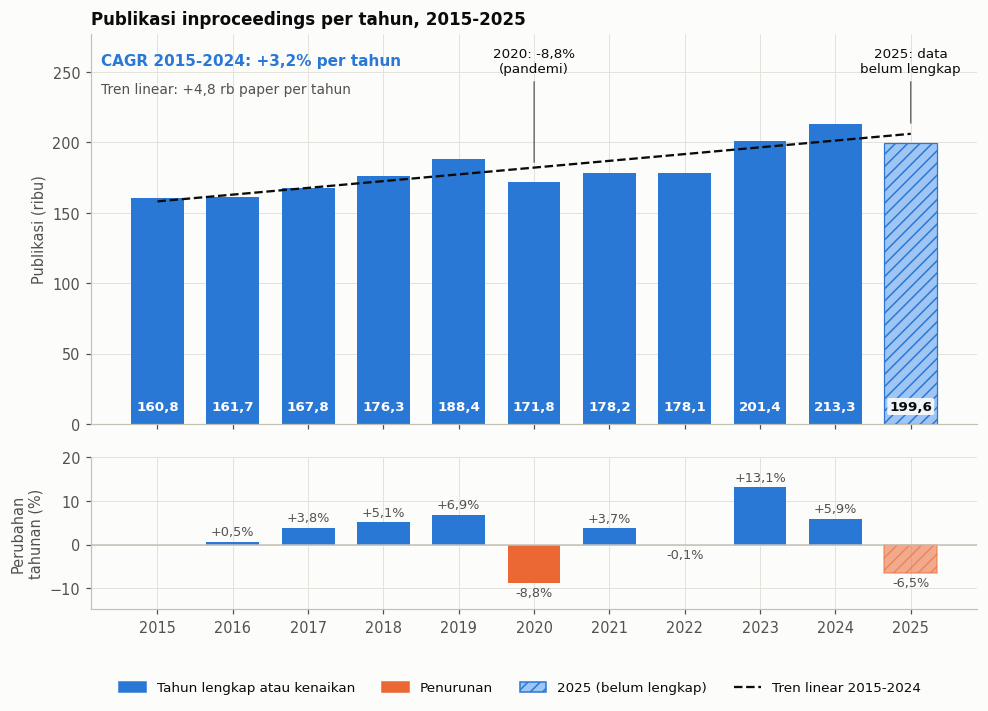

In [37]:
years = per_year.index.values
values = per_year.values
yoy = per_year.pct_change().dropna() * 100

fig = plt.figure(figsize=(10.4, 6.8))
grid = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.25], hspace=0.12)
ax = fig.add_subplot(grid[0])
ax_yoy = fig.add_subplot(grid[1], sharex=ax)

bar_colors = [CFG.BLUE if y < CFG.YEAR_INCOMPLETE else CFG.BLUE_LIGHT for y in years]
bars = ax.bar(years, values / 1e3, color=bar_colors, width=0.7, zorder=2)
bars[-1].set_hatch("///")
bars[-1].set_edgecolor(CFG.BLUE)
bars[-1].set_linewidth(0.8)
for x, v in zip(years, values):
    complete_year = x < CFG.YEAR_INCOMPLETE
    ax.text(x, 8, fmt_id(v / 1e3, 1), ha="center", va="bottom", fontsize=8.8, fontweight="bold",
            color="#ffffff" if complete_year else CFG.INK,
            bbox=None if complete_year else dict(boxstyle="round,pad=0.15", fc=CFG.SURFACE, ec="none", alpha=0.9))
ax.plot(years, (slope * years + intercept) / 1e3, color=CFG.INK, ls="--", lw=1.5, zorder=3)

ax.set_ylim(0, values.max() / 1e3 * 1.3)
ax.set_ylabel("Publikasi (ribu)")
ax.set_title("Publikasi inproceedings per tahun, 2015-2025")
plt.setp(ax.get_xticklabels(), visible=False)

ax.text(0.012, 0.95, "CAGR 2015-2024: +" + f"{cagr * 100:.1f}".replace(".", ",") + "% per tahun",
        transform=ax.transAxes, fontsize=10, fontweight="bold", color=CFG.BLUE, va="top")
ax.text(0.012, 0.875, f"Tren linear: +{fmt_id(slope / 1e3, 1)} rb paper per tahun",
        transform=ax.transAxes, fontsize=9, color=CFG.INK_2, va="top")

top_y = values.max() / 1e3 * 1.17
ax.annotate("2020: " + f"{yoy.loc[2020]:.1f}".replace(".", ",") + "%\n(pandemi)", xy=(2020, per_year.loc[2020] / 1e3 + 12),
            xytext=(2020, top_y), ha="center", fontsize=8.8, color=CFG.INK,
            arrowprops=dict(arrowstyle="-", color=CFG.INK_2, lw=0.8))
ax.annotate("2025: data\nbelum lengkap", xy=(2025, per_year.loc[2025] / 1e3 + 12),
            xytext=(2025, top_y), ha="center", fontsize=8.8, color=CFG.INK,
            arrowprops=dict(arrowstyle="-", color=CFG.INK_2, lw=0.8))

yoy_bars = ax_yoy.bar(yoy.index, yoy.values, color=[CFG.BLUE if v >= 0 else CFG.ORANGE for v in yoy.values], width=0.7, zorder=2)
yoy_bars[-1].set_hatch("///")
yoy_bars[-1].set_alpha(0.55)
yoy_bars[-1].set_edgecolor(CFG.ORANGE if yoy.iloc[-1] < 0 else CFG.BLUE)
for x, v in zip(yoy.index, yoy.values):
    ax_yoy.text(x, v + (0.8 if v >= 0 else -0.8), f"{v:+.1f}%".replace(".", ","), ha="center",
                va="bottom" if v >= 0 else "top", fontsize=8.4, color=CFG.INK_2)
ax_yoy.axhline(0, color=CFG.BASELINE, lw=1)
ax_yoy.set_ylim(yoy.min() - 6, yoy.max() + 7)
ax_yoy.set_ylabel("Perubahan\ntahunan (%)")
ax_yoy.set_xticks(years)

fig.legend(handles=[Patch(color=CFG.BLUE, label="Tahun lengkap atau kenaikan"), Patch(color=CFG.ORANGE, label="Penurunan"),
                    Patch(facecolor=CFG.BLUE_LIGHT, hatch="///", edgecolor=CFG.BLUE, label="2025 (belum lengkap)"),
                    Line2D([], [], color=CFG.INK, ls="--", label="Tren linear 2015-2024")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02), fontsize=8.8)
save_fig(fig, "t1_publikasi_per_tahun.png")

#### Insights

> Jumlah publikasi naik dari 160.800 pada 2015 menjadi 213.328 pada 2024 (+32,7%), setara CAGR 3,2% per tahun atau sekitar 4.800 paper tambahan setiap tahun. Pertumbuhan ini tidak mulus: 2020 turun 8,8%, dan jumlahnya tetap di bawah garis tren sampai 2022 (-5,7%, -4,7%, dan -7,1%), lalu melonjak 13,1% pada 2023 hingga kembali di atas tren. Penurunan 2020 kemungkinan terkait pandemi, tetapi data ini tidak memuat penyebabnya sehingga hubungan itu hanya dugaan.

> Penurunan 2025 (-6,5%) tidak dapat dibaca sebagai turunnya aktivitas. Ada 789 konferensi yang aktif pada 2024 tetapi kosong pada 2025, dan konferensi itu menyumbang 49.328 paper atau 23,1% dari total 2024. Penyebabnya ada dua. Konferensi dua tahunan genap seperti ECCV dan ICPR hanya memiliki data pada 2020, 2022, dan 2024, sedangkan konferensi tahunan seperti IGARSS, EMBC, dan ICCCNT memiliki data setiap tahun sampai 2024 lalu kosong pada 2025, yang menandakan prosidingnya belum terindeks.

> Jika konferensi yang kosong itu dikeluarkan, jumlah paper 2025 justru 21,7% di atas 2024. Angka ini bukan ukuran pertumbuhan yang adil, karena 322 konferensi yang hanya aktif pada 2025 (umumnya konferensi dua tahunan ganjil, 17.785 paper) tetap ikut terhitung. Karena itu 2025 digambar dengan arsiran dan tidak dipakai untuk menghitung tren.

## 5.3 Distribusi Publikasi per Konferensi

Distribusi per konferensi dibaca dari tiga sisi. Bar chart memperlihatkan 20 konferensi terbesar beserta porsinya, kurva kumulatif memperlihatkan seberapa terkonsentrasi publikasi pada sedikit konferensi, dan histogram berskala logaritmik memperlihatkan bentuk seluruh distribusi ukuran konferensi. Nama lengkap konferensi dicantumkan pada tabel dari judul prosiding terbaru di dump.

In [38]:
pub_venue = clean.groupby("venue").size().sort_values(ascending=False)
share = pub_venue / pub_venue.sum() * 100
cum = share.cumsum()
proceedings_title = venue_proceedings.set_index("venue")["proceedings_title"]

top20 = pd.DataFrame({
    "venue": pub_venue.head(20).index,
    "nama": [display_name(v) for v in pub_venue.head(20).index],
    "publikasi": pub_venue.head(20).values,
    "porsi_%": share.head(20).values,
    "kumulatif_%": cum.head(20).values,
    "judul_prosiding_terbaru": [str(proceedings_title.get(v, ""))[:72] for v in pub_venue.head(20).index],
})
save_table(top20, "t1_top20_venue.csv", index=False)
save_table(pub_venue.rename("publikasi").to_frame(), "t1_publikasi_per_venue.csv")

rank_50 = int((cum < 50).sum() + 1)
rank_80 = int((cum < 80).sum() + 1)
n_small = int((pub_venue < 50).sum())
print(f"Venue untuk 50% publikasi: {rank_50:,} ({rank_50 / len(pub_venue):.1%}) | untuk 80%: {rank_80:,} ({rank_80 / len(pub_venue):.1%})")
print(f"Median {pub_venue.median():,.0f} paper | rata-rata {pub_venue.mean():,.0f} | maksimum {pub_venue.max():,} | venue < 50 paper: {n_small:,} ({n_small / len(pub_venue):.1%})")
top20

Venue untuk 50% publikasi: 231 (5.3%) | untuk 80%: 1,011 (23.1%)
Median 134 paper | rata-rata 457 | maksimum 25,455 | venue < 50 paper: 1,358 (31.1%)


,venue,nama,publikasi,porsi_%,kumulatif_%,judul_prosiding_terbaru
0,nips,NeurIPS,25455,1.274506,1.274506,Advances in Neural Information Processing Systems 38: Annual Conference
1,cvpr,CVPR,22751,1.139120,2.413626,"IEEE/CVF Conference on Computer Vision and Pattern Recognition, CVPR 202"
2,icassp,ICASSP,21606,1.081791,3.495417,"2025 IEEE International Conference on Acoustics, Speech and Signal Proce"
3,hci,HCI,19912,0.996974,4.492391,HCI International 2024 - Late Breaking Papers - 26th International Confe
4,igarss,IGARSS,19685,0.985608,5.477999,IGARSS 2024 - 2024 IEEE International Geoscience and Remote Sensing Symp
5,aaai,AAAI,19274,0.965030,6.443028,"Thirty-Ninth AAAI Conference on Artificial Intelligence, Thirty-Seventh"
6,chi,CHI,14832,0.742623,7.185652,Proceedings of the 2025 CHI Conference on Human Factors in Computing Sys
7,emnlp,EMNLP,14813,0.741672,7.927324,Proceedings of the 2025 Conference on Empirical Methods in Natural Langu
8,embc,EMBC,14676,0.734813,8.662136,46th Annual International Conference of the IEEE Engineering in Medicine
9,icc,ICC,14329,0.717439,9.379575,"IEEE International Conference on Communications, ICC 2025, Montreal, QC,"


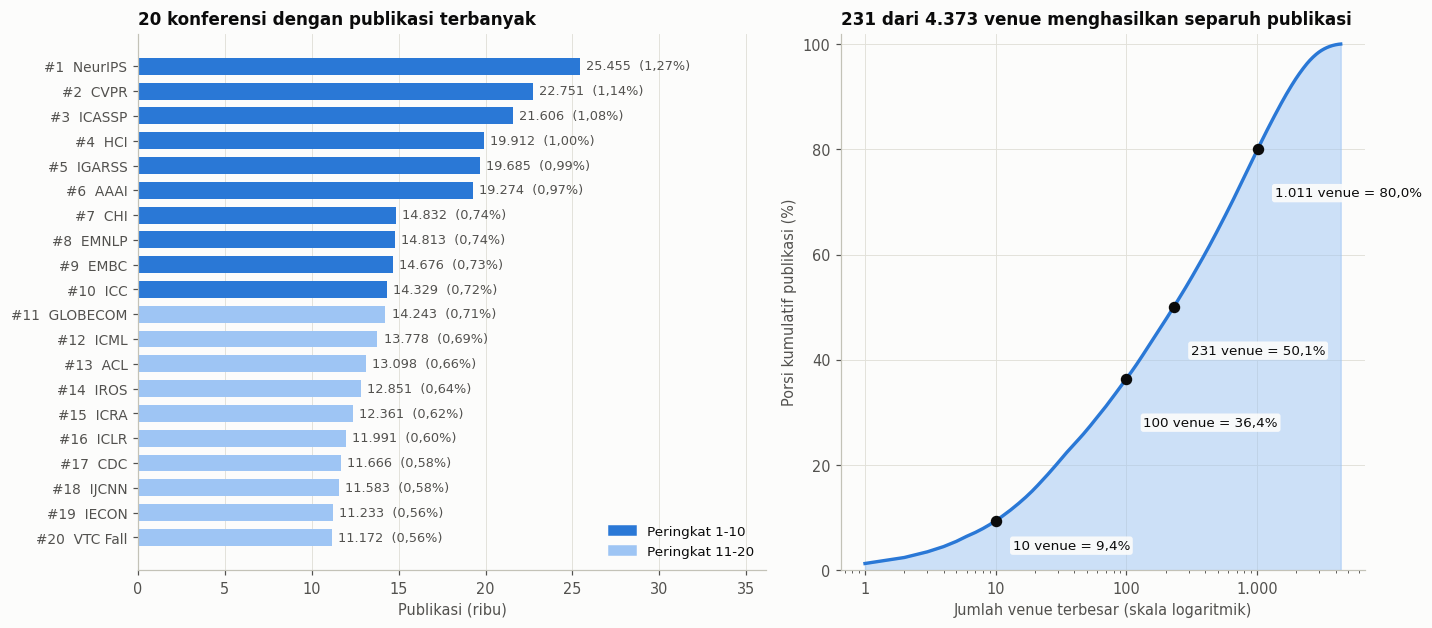

In [39]:
fig, (ax_bar, ax_cum) = plt.subplots(1, 2, figsize=(13.2, 5.8), gridspec_kw={"width_ratios": [1.2, 1]})

t = top20.iloc[::-1].reset_index(drop=True)
bar_colors = [CFG.BLUE if i >= 10 else CFG.BLUE_LIGHT for i in range(len(t))]
ax_bar.barh(np.arange(len(t)), t["publikasi"] / 1e3, color=bar_colors, height=0.68, zorder=2)
for y, row in t.iterrows():
    ax_bar.text(row["publikasi"] / 1e3 + 0.35, y, f"{fmt_id(row['publikasi'])}  ({pct_id(row['porsi_%'], 2)})",
                va="center", fontsize=8.4, color=CFG.INK_2)
ax_bar.set_yticks(np.arange(len(t)))
ax_bar.set_yticklabels([f"#{len(t) - i}  {name}" for i, name in enumerate(t["nama"])], fontsize=9)
ax_bar.set_xlim(0, t["publikasi"].max() / 1e3 * 1.42)
ax_bar.set_xlabel("Publikasi (ribu)")
ax_bar.grid(axis="y", visible=False)
ax_bar.set_title("20 konferensi dengan publikasi terbanyak")
ax_bar.legend(handles=[Patch(color=CFG.BLUE, label="Peringkat 1-10"), Patch(color=CFG.BLUE_LIGHT, label="Peringkat 11-20")],
              loc="lower right", fontsize=8.8)

ranks = np.arange(1, len(cum) + 1)
ax_cum.fill_between(ranks, cum.values, color=CFG.BLUE_LIGHT, alpha=0.5, zorder=1)
ax_cum.plot(ranks, cum.values, color=CFG.BLUE, lw=2.2, zorder=3)
for rank in (10, 100, rank_50, rank_80):
    ax_cum.scatter(rank, cum.iloc[rank - 1], s=42, color=CFG.INK, zorder=4)
    ax_cum.annotate(f"{fmt_id(rank)} venue = {pct_id(cum.iloc[rank - 1], 1)}", xy=(rank, cum.iloc[rank - 1]),
                    xytext=(rank * 1.35, max(cum.iloc[rank - 1] - 9, 4)), fontsize=8.8,
                    bbox=dict(boxstyle="round,pad=0.2", fc=CFG.SURFACE, ec="none", alpha=0.9))
ax_cum.set_xscale("log")
ax_cum.set_xticks([1, 10, 100, 1000])
ax_cum.set_xticklabels(["1", "10", "100", "1.000"])
ax_cum.set_ylim(0, 102)
ax_cum.set_xlabel("Jumlah venue terbesar (skala logaritmik)")
ax_cum.set_ylabel("Porsi kumulatif publikasi (%)")
ax_cum.set_title(f"{fmt_id(rank_50)} dari {fmt_id(len(cum))} venue menghasilkan separuh publikasi")
fig.tight_layout()
save_fig(fig, "t1_publikasi_per_konferensi.png")

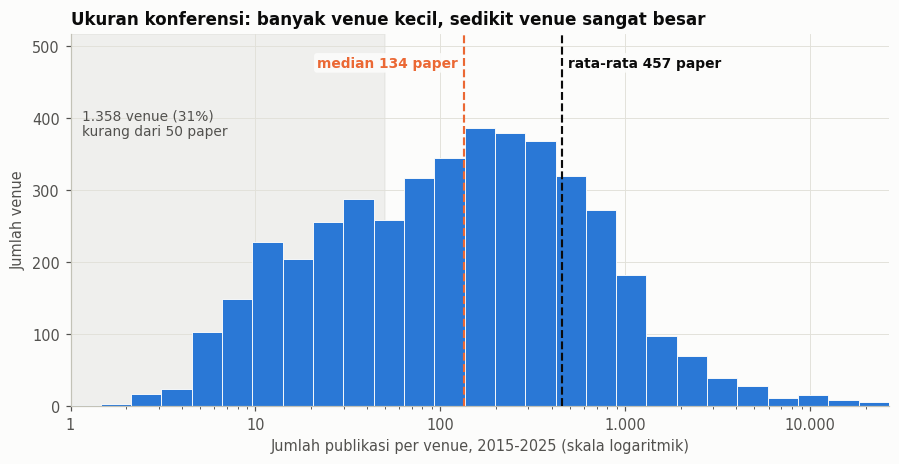

In [40]:
bins = np.logspace(0, np.log10(pub_venue.max() * 1.05), 28)
counts, edges = np.histogram(pub_venue.values, bins=bins)

fig, ax = plt.subplots(figsize=(9.6, 4.4))
ax.axvspan(1, 50, color=CFG.GRAY, alpha=0.18, zorder=0)
ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=CFG.BLUE, edgecolor=CFG.SURFACE, linewidth=0.6, zorder=2)
ax.set_xscale("log")
ax.set_xlim(1, bins[-1])
ax.set_xticks([1, 10, 100, 1000, 10000])
ax.set_xticklabels(["1", "10", "100", "1.000", "10.000"])
ax.set_ylim(0, counts.max() * 1.34)
label_box = dict(boxstyle="round,pad=0.2", fc=CFG.SURFACE, ec="none", alpha=0.92)
for stat, label, color, side in ((pub_venue.median(), "median", CFG.ORANGE, "left"), (pub_venue.mean(), "rata-rata", CFG.INK, "right")):
    ax.axvline(stat, color=color, lw=1.4, ls="--", zorder=3)
    ax.text(stat / 1.08 if side == "left" else stat * 1.08, counts.max() * 1.22, f"{label} {fmt_id(stat)} paper",
            color=color, fontsize=9, fontweight="bold", ha="right" if side == "left" else "left", bbox=label_box)
ax.text(1.15, counts.max() * 1.07, f"{fmt_id(n_small)} venue ({pct_id(n_small / len(pub_venue) * 100, 0)})\nkurang dari 50 paper",
        fontsize=9, color=CFG.INK_2, va="top")
ax.set_xlabel("Jumlah publikasi per venue, 2015-2025 (skala logaritmik)")
ax.set_ylabel("Jumlah venue")
ax.set_title("Ukuran konferensi: banyak venue kecil, sedikit venue sangat besar")
save_fig(fig, "t1_distribusi_ukuran_venue.png")

#### Insights

> Publikasi sangat terkonsentrasi pada sedikit konferensi. Sepuluh konferensi teratas menghasilkan 9,4% seluruh paper dan 20 teratas 15,6%. Sebanyak 231 dari 4.373 venue (5,3%) sudah menghasilkan separuh publikasi, dan 1.011 venue (23,1%) menghasilkan 80%.

> Sisi sebaliknya adalah ekor panjang yang tebal. Median venue hanya 134 paper, jauh di bawah rata-rata 457 yang ditarik oleh venue raksasa (maksimum 25.455 paper), dan 1.358 venue (31%) memiliki kurang dari 50 paper dalam sebelas tahun.

> Di antara 20 konferensi terbesar, NeurIPS (25.455), CVPR (22.751), ICASSP (21.606), HCI (HCI International, 19.912), IGARSS (19.685), dan AAAI (19.274) membentuk kelompok atas di atas 19.000 paper. Peringkat 7 sampai 10 berada rapat pada 14.300 sampai 14.800 paper, sehingga selisih antarperingkat di sana sangat kecil.

## 5.4 Distribusi Author

Produktivitas author menentukan seberapa padat transaksi yang akan dibentuk pada task berikutnya. Karena perbandingannya berupa porsi dari keseluruhan, dipakai waffle chart yang dalam panduan Datawrapper adalah alternatif yang lebih mudah dibaca daripada pie chart. Dua waffle disandingkan dengan warna yang sama: porsi jumlah author dan porsi pasangan paper-author yang mereka tulis.

In [41]:
tiers = pd.cut(papers_per_author, bins=[0, 1, 3, 10, 50, np.inf],
               labels=["1 paper", "2-3 paper", "4-10 paper", "11-50 paper", ">50 paper"])
tier_table = pd.DataFrame({
    "author": tiers.value_counts().sort_index(),
    "pasangan_paper_author": papers_per_author.groupby(tiers, observed=False).sum(),
})
tier_table["author_%"] = tier_table["author"] / tier_table["author"].sum() * 100
tier_table["pasangan_%"] = tier_table["pasangan_paper_author"] / tier_table["pasangan_paper_author"].sum() * 100
save_table(tier_table, "t1_produktivitas_author.csv")
print(f"Author paling produktif: {papers_per_author.idxmax()} ({papers_per_author.max()} paper)")
tier_table.round(1)

Author paling produktif: Yang Liu (725 paper)


,author,pasangan_paper_author,author_%,pasangan_%
1 paper,936884,936884,51.4,11.9
2-3 paper,434849,1015531,23.9,12.9
4-10 paper,299130,1778866,16.4,22.6
11-50 paper,135073,2769731,7.4,35.2
>50 paper,15821,1369890,0.9,17.4


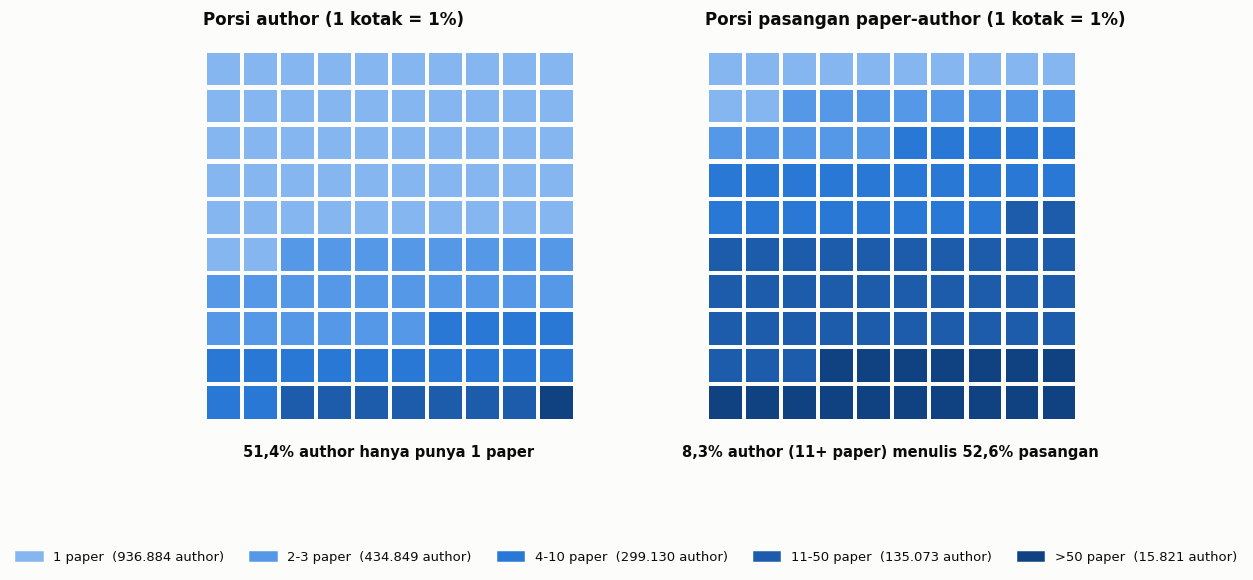

In [42]:
def waffle_counts(shares, total=100):
    exact = np.asarray(shares, dtype=float) / np.sum(shares) * total
    counts = np.floor(exact).astype(int)
    for i in np.argsort(-(exact - counts))[: total - counts.sum()]:
        counts[i] += 1
    return counts

def draw_waffle(ax, counts, colors):
    index = 0
    for tier, count in enumerate(counts):
        for _ in range(count):
            row, col = divmod(index, 10)
            ax.add_patch(Rectangle((col, 9 - row), 0.88, 0.88, facecolor=colors[tier], edgecolor="none"))
            index += 1
    ax.set_xlim(-0.1, 10)
    ax.set_ylim(-2.4, 10.4)
    ax.set_aspect("equal")
    ax.axis("off")

heavy_author = tier_table["author_%"].iloc[3:].sum()
heavy_pairs = tier_table["pasangan_%"].iloc[3:].sum()

fig, axes = plt.subplots(1, 2, figsize=(10.8, 5.6))
draw_waffle(axes[0], waffle_counts(tier_table["author_%"]), CFG.ORDINAL)
draw_waffle(axes[1], waffle_counts(tier_table["pasangan_%"]), CFG.ORDINAL)
axes[0].set_title("Porsi author (1 kotak = 1%)")
axes[1].set_title("Porsi pasangan paper-author (1 kotak = 1%)")
axes[0].text(4.9, -1.0, f"{pct_id(tier_table['author_%'].iloc[0])} author hanya punya 1 paper", ha="center", fontsize=9.6, fontweight="bold", color=CFG.INK)
axes[1].text(4.9, -1.0, f"{pct_id(heavy_author)} author (11+ paper) menulis {pct_id(heavy_pairs)} pasangan", ha="center",
             fontsize=9.6, fontweight="bold", color=CFG.INK)
fig.legend(handles=[Patch(color=c, label=f"{label}  ({fmt_id(n)} author)") for c, label, n in
                    zip(CFG.ORDINAL, tier_table.index, tier_table["author"])],
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.0), fontsize=8.6)
save_fig(fig, "t1_produktivitas_author.png")

#### Insights

> Produktivitas author sangat timpang. Sebanyak 51,4% author hanya menulis satu paper, tetapi mereka hanya menyumbang 11,9% pasangan paper-author. Sebaliknya, 8,3% author yang menulis 11 paper atau lebih (150.894 orang) menyumbang 52,6% pasangan.

> Konsekuensinya bagi mining, pola konferensi yang muncul bersama kelak diperkirakan lebih banyak dibentuk oleh kelompok kecil author yang menerbitkan di banyak konferensi, bukan oleh mayoritas author yang hanya sekali menerbitkan. Author paling produktif adalah `Yang Liu` (725 paper), yaitu nama umum yang kemungkinan menggabungkan banyak orang berbeda (lihat bagian 4.7).

---

---

# PART II | TASK 2: Conference Popularity Analysis <a name="part2"></a>

*Mengidentifikasi konferensi dengan aktivitas publikasi tertinggi dan menganalisis tren serta perbandingan peringkatnya.*

---

---

---

# Analisis Popularitas Konferensi (Task 2) <a name="6"></a>

---

Popularitas konferensi pada tugas ini diukur dari aktivitas publikasi, dengan dua ukuran yang saling melengkapi. Jumlah publikasi menunjukkan seberapa banyak karya yang diterbitkan, sedangkan jumlah author unik menunjukkan seberapa luas komunitas yang terlibat. Seluruh perhitungan memakai data hasil preprocessing, dengan venue yang diidentifikasi dari `key` DBLP.

## 6.1 Sepuluh Konferensi dengan Publikasi Terbanyak (Task 2.1)

Peringkat disusun dari jumlah paper per konferensi. Hasilnya ditampilkan sebagai bar chart horizontal, bentuk yang dalam panduan Datawrapper paling tepat untuk membandingkan angka absolut. Warna gelap menandai konferensi yang juga masuk 10 besar menurut jumlah author unik, dan angka di ujung batang menyebutkan peringkatnya pada ukuran lain, sehingga perbandingan pada Task 2.4 sudah terlihat sejak awal.

In [43]:
auth_venue = pa.groupby("venue")["author"].nunique()
pairs_venue = pa.groupby("venue").size()

venue_stats = pd.DataFrame({"publikasi": pub_venue, "author_unik": auth_venue, "pasangan_paper_author": pairs_venue})
venue_stats["rank_publikasi"] = venue_stats["publikasi"].rank(ascending=False, method="min").astype(int)
venue_stats["rank_author"] = venue_stats["author_unik"].rank(ascending=False, method="min").astype(int)
venue_stats["porsi_publikasi_%"] = venue_stats["publikasi"] / venue_stats["publikasi"].sum() * 100
venue_stats["paper_per_author"] = venue_stats["pasangan_paper_author"] / venue_stats["author_unik"]
venue_stats["author_unik_per_paper"] = venue_stats["author_unik"] / venue_stats["publikasi"]
venue_stats["nama"] = [display_name(v) for v in venue_stats.index]
save_table(venue_stats.sort_values("rank_publikasi"), "t2_statistik_venue.csv")

top_pub = venue_stats.sort_values("rank_publikasi").head(10)
top_auth = venue_stats.sort_values("rank_author").head(10)
shared = set(top_pub.index) & set(top_auth.index)

print(f"Batas 10 besar jelas (tanpa seri): publikasi {top_pub['publikasi'].min() > venue_stats['publikasi'].drop(top_pub.index).max()}, "
      f"author {top_auth['author_unik'].min() > venue_stats['author_unik'].drop(top_auth.index).max()}")
top_pub[["nama", "publikasi", "porsi_publikasi_%", "rank_author", "author_unik"]].round(2)

Batas 10 besar jelas (tanpa seri): publikasi True, author True


,nama,publikasi,porsi_publikasi_%,rank_author,author_unik
venue,,,,,
nips,NeurIPS,25455,1.27,1,57800
cvpr,CVPR,22751,1.14,2,47664
icassp,ICASSP,21606,1.08,4,42057
hci,HCI,19912,1.00,6,37884
igarss,IGARSS,19685,0.99,7,35229
aaai,AAAI,19274,0.97,3,46437
chi,CHI,14832,0.74,12,29904
emnlp,EMNLP,14813,0.74,8,33954
embc,EMBC,14676,0.73,5,39318


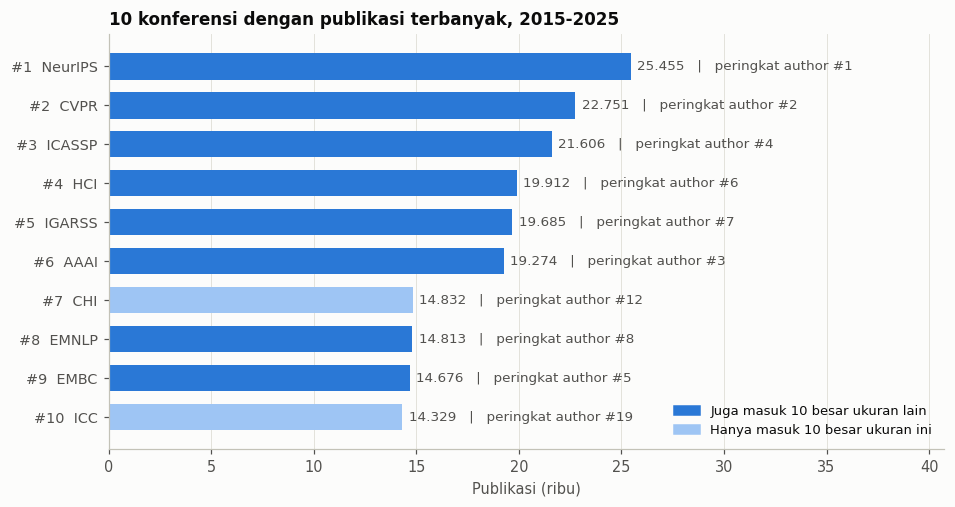

In [44]:
def rank_bar(ax, table, value_col, other_rank_col, other_label, xlabel, title):
    t = table.iloc[::-1]
    colors = [CFG.BLUE if venue in shared else CFG.BLUE_LIGHT for venue in t.index]
    ax.barh(np.arange(len(t)), t[value_col] / 1e3, color=colors, height=0.68, zorder=2)
    offset = t[value_col].max() / 1e3 * 0.012
    for y, (venue, row) in enumerate(t.iterrows()):
        ax.text(row[value_col] / 1e3 + offset, y, f"{fmt_id(row[value_col])}   |   {other_label} #{int(row[other_rank_col])}",
                va="center", fontsize=8.8, color=CFG.INK_2)
    ax.set_yticks(np.arange(len(t)))
    ax.set_yticklabels([f"#{len(t) - i}  {name}" for i, name in enumerate(t["nama"])], fontsize=9.4)
    ax.set_xlim(0, t[value_col].max() / 1e3 * 1.6)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.legend(handles=[Patch(color=CFG.BLUE, label="Juga masuk 10 besar ukuran lain"),
                       Patch(color=CFG.BLUE_LIGHT, label="Hanya masuk 10 besar ukuran ini")],
              loc="lower right", fontsize=8.6)

fig, ax = plt.subplots(figsize=(9.8, 4.9))
rank_bar(ax, top_pub, "publikasi", "rank_author", "peringkat author", "Publikasi (ribu)",
         "10 konferensi dengan publikasi terbanyak, 2015-2025")
save_fig(fig, "t2_top10_publikasi.png")

#### Insights

> Konferensi dengan publikasi terbanyak adalah NeurIPS (25.455 paper, 1,27% dari seluruh dataset), disusul CVPR (22.751), ICASSP (21.606), HCI (19.912), IGARSS (19.685), dan AAAI (19.274). Sepuluh konferensi teratas menghasilkan 9,4% seluruh publikasi.

> Daftar ini bercampur lintas bidang: kecerdasan buatan dan pemrosesan bahasa (NeurIPS, CVPR, AAAI, EMNLP), pemrosesan sinyal dan penginderaan jauh (ICASSP, IGARSS), interaksi manusia dan komputer (HCI, CHI), serta teknik biomedis dan komunikasi (EMBC, ICC). Tidak ada satu bidang yang mendominasi, tetapi bidang kecerdasan buatan menempati empat dari sepuluh tempat.

> Batas 10 besar sangat tipis: ICC di peringkat 10 (14.329 paper) hanya unggul 86 paper dari GLOBECOM di peringkat 11 (14.243). Daftar ini juga bergantung pada keputusan menggabungkan workshop ke konferensi induknya, yang diuji pada subbagian 6.5.

## 6.2 Sepuluh Konferensi dengan Author Unik Terbanyak (Task 2.2)

Ukuran kedua menghitung berapa orang berbeda yang pernah menerbitkan paper di sebuah konferensi. Satu orang dihitung sekali per konferensi, berapa pun jumlah papernya, sehingga ukuran ini lebih mencerminkan luas komunitas daripada volume karya. Bentuk chart dan kode warna sama dengan subbagian sebelumnya agar kedua peringkat dapat dibandingkan langsung.

In [45]:
top_auth[["nama", "author_unik", "rank_publikasi", "publikasi", "paper_per_author"]].round(2)

,nama,author_unik,rank_publikasi,publikasi,paper_per_author
venue,,,,,
nips,NeurIPS,57800,1,25455,2.18
cvpr,CVPR,47664,2,22751,2.50
aaai,AAAI,46437,6,19274,1.83
icassp,ICASSP,42057,3,21606,2.11
embc,EMBC,39318,9,14676,1.84
hci,HCI,37884,4,19912,1.83
igarss,IGARSS,35229,5,19685,2.64
emnlp,EMNLP,33954,8,14813,2.16
icml,ICML,31896,12,13778,1.95


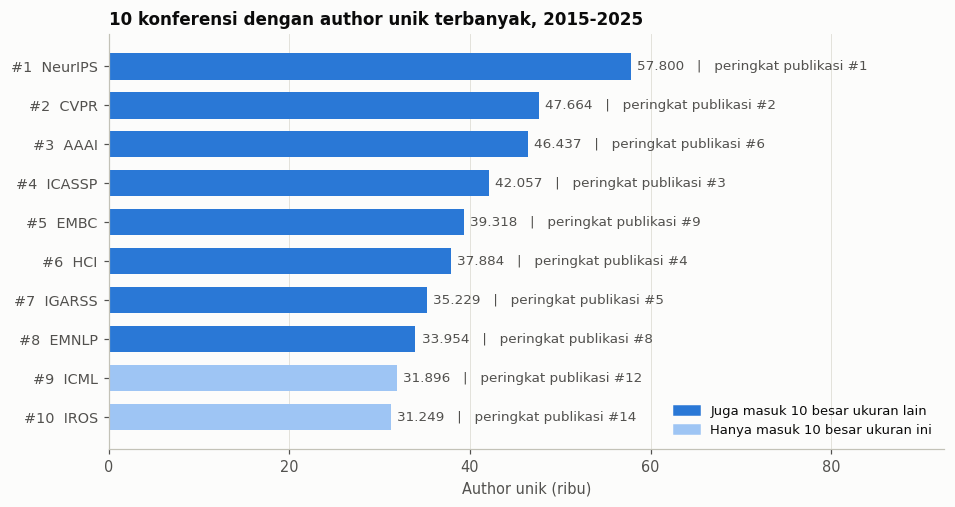

In [46]:
fig, ax = plt.subplots(figsize=(9.8, 4.9))
rank_bar(ax, top_auth, "author_unik", "rank_publikasi", "peringkat publikasi", "Author unik (ribu)",
         "10 konferensi dengan author unik terbanyak, 2015-2025")
save_fig(fig, "t2_top10_author.png")

#### Insights

> Konferensi dengan author unik terbanyak juga NeurIPS (57.800 author), diikuti CVPR (47.664), AAAI (46.437), ICASSP (42.057), dan EMBC (39.318). Pada seluruh konferensi di daftar ini, jumlah author unik lebih besar daripada jumlah paper, karena satu paper ditulis oleh beberapa orang.

> Ukuran paper per author menunjukkan seberapa sering author yang sama kembali. IGARSS (2,64) dan CVPR (2,50) tertinggi pada daftar ini, artinya rata-rata author menerbitkan 2 sampai 3 paper di sana. AAAI, HCI, IROS, dan EMBC terendah (sekitar 1,83), artinya komunitasnya lebih luas dan lebih banyak author yang hanya muncul satu kali.

## 6.3 Tren Publikasi per Tahun (Task 2.3)

Tren dianalisis untuk 10 konferensi dengan publikasi terbanyak. Karena setiap konferensi berbeda skalanya, dipakai small multiples, yaitu satu panel per konferensi dengan sumbu vertikal yang sama sehingga ukuran dan kemiringannya dapat dibandingkan langsung. Setiap panel memuat garis jumlah paper, garis tren linear 2015-2024, dan titik berongga untuk 2025 yang indeksnya belum lengkap. Laju pertumbuhan diringkas dengan kelipatan 2015 ke 2024 dan CAGR.

In [47]:
trend = clean.groupby(["venue", "year"]).size().unstack(fill_value=0)
trend.columns = trend.columns.astype(int)
top_venues = list(top_pub.index)
trend_top = trend.loc[top_venues]

def growth_stats(row):
    series = row.loc[CFG.YEAR_MIN:CFG.YEAR_INCOMPLETE - 1]
    slope_v, _ = np.polyfit(series.index.values.astype(float), series.values.astype(float), 1)
    ratio = series.iloc[-1] / series.iloc[0]
    return pd.Series({
        "publikasi_2015": series.iloc[0],
        "publikasi_2024": series.iloc[-1],
        "kali_lipat": ratio,
        "cagr_%": (ratio ** (1 / (len(series) - 1)) - 1) * 100,
        "tambahan_per_tahun": slope_v,
        "publikasi_2025": row.loc[CFG.YEAR_INCOMPLETE],
        "perubahan_2025_vs_2024_%": (row.loc[CFG.YEAR_INCOMPLETE] / row.loc[CFG.YEAR_INCOMPLETE - 1] - 1) * 100,
    })

growth = trend_top.apply(growth_stats, axis=1)
growth.insert(0, "nama", [display_name(v) for v in growth.index])
save_table(growth, "t2_tren_top10.csv")

top10_share = (trend_top.sum() / per_year * 100).rename("porsi_top10_%")
print("Porsi 10 konferensi teratas terhadap seluruh publikasi per tahun (%):")
print(top10_share.round(2).to_string())
growth.round(1)

Porsi 10 konferensi teratas terhadap seluruh publikasi per tahun (%):
year
2015     6.99
2016     6.81
2017     6.54
2018     7.46
2019     8.17
2020     9.79
2021    10.04
2022    10.05
2023    11.06
2024    11.73
2025    12.88


,nama,publikasi_2015,publikasi_2024,kali_lipat,cagr_%,tambahan_per_tahun,publikasi_2025,perubahan_2025_vs_2024_%
venue,,,,,,,,
nips,NeurIPS,440.0,4494.0,10.2,29.5,442.8,5823.0,29.6
cvpr,CVPR,733.0,3531.0,4.8,19.1,310.0,3543.0,0.3
icassp,ICASSP,1198.0,2895.0,2.4,10.3,183.6,3370.0,16.4
hci,HCI,1713.0,1801.0,1.1,0.6,68.2,2327.0,29.2
igarss,IGARSS,1353.0,2589.0,1.9,7.5,80.2,0.0,-100.0
aaai,AAAI,790.0,2882.0,3.6,15.5,209.5,3508.0,21.7
chi,CHI,930.0,1705.0,1.8,7.0,61.7,2168.0,27.2
emnlp,EMNLP,324.0,2450.0,7.6,25.2,247.4,3491.0,42.5
embc,EMBC,2004.0,1386.0,0.7,-4.0,-47.0,0.0,-100.0


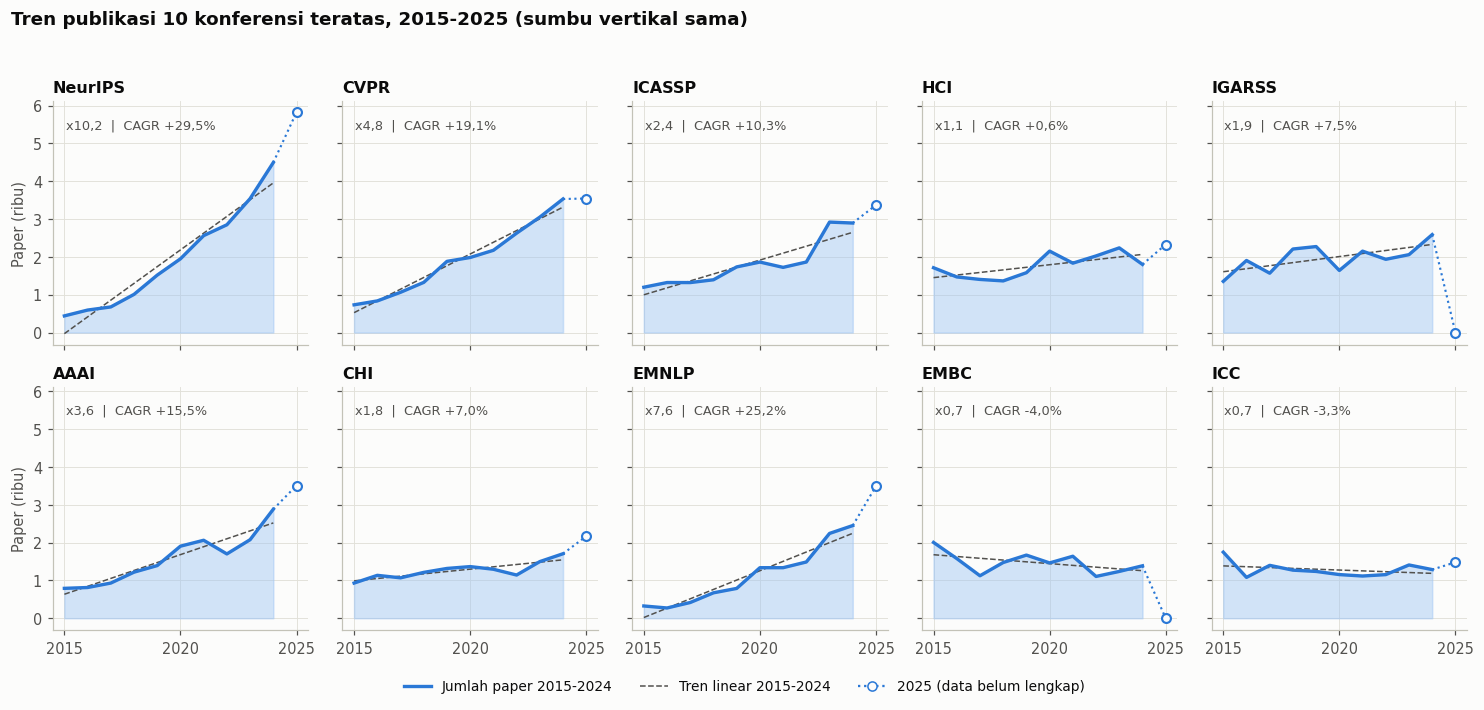

In [48]:
fig, axes = plt.subplots(2, 5, figsize=(13.6, 6.2), sharex=True, sharey=True)
full_years = np.arange(CFG.YEAR_MIN, CFG.YEAR_INCOMPLETE)

for ax, venue in zip(axes.flat, top_venues):
    row = trend_top.loc[venue]
    series = row.loc[CFG.YEAR_MIN:CFG.YEAR_INCOMPLETE - 1].values / 1e3
    slope_v, intercept_v = np.polyfit(full_years.astype(float), series, 1)
    ax.fill_between(full_years, series, color=CFG.BLUE_LIGHT, alpha=0.45, zorder=1)
    ax.plot(full_years, slope_v * full_years + intercept_v, color=CFG.INK_2, ls="--", lw=1.0, zorder=2)
    ax.plot(full_years, series, color=CFG.BLUE, lw=2.2, zorder=3)
    ax.plot([CFG.YEAR_INCOMPLETE - 1, CFG.YEAR_INCOMPLETE], [series[-1], row.loc[CFG.YEAR_INCOMPLETE] / 1e3],
            color=CFG.BLUE, lw=1.4, ls=":", zorder=3)
    ax.scatter([CFG.YEAR_INCOMPLETE], [row.loc[CFG.YEAR_INCOMPLETE] / 1e3], s=34, facecolor=CFG.SURFACE,
               edgecolor=CFG.BLUE, lw=1.4, zorder=4)
    g = growth.loc[venue]
    ax.set_title(display_name(venue), fontsize=10.5)
    ax.text(0.05, 0.93, f"x{g['kali_lipat']:.1f}  |  CAGR {g['cagr_%']:+.1f}%".replace(".", ","),
            transform=ax.transAxes, fontsize=8.4, va="top", color=CFG.INK_2)
    ax.set_xticks([2015, 2020, 2025])
for ax in axes[:, 0]:
    ax.set_ylabel("Paper (ribu)")

fig.suptitle("Tren publikasi 10 konferensi teratas, 2015-2025 (sumbu vertikal sama)", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.0)
fig.legend(handles=[Line2D([], [], color=CFG.BLUE, lw=2.2, label="Jumlah paper 2015-2024"),
                    Line2D([], [], color=CFG.INK_2, ls="--", lw=1.0, label="Tren linear 2015-2024"),
                    Line2D([], [], color=CFG.BLUE, ls=":", marker="o", mfc=CFG.SURFACE, mec=CFG.BLUE, label="2025 (data belum lengkap)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02), fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
save_fig(fig, "t2_tren_top10.png")

Laju pertumbuhan 10 konferensi dibandingkan dalam satu chart. Garis putus-putus menandai CAGR seluruh dataset, sehingga terlihat konferensi mana yang tumbuh lebih cepat atau lebih lambat daripada keseluruhan.

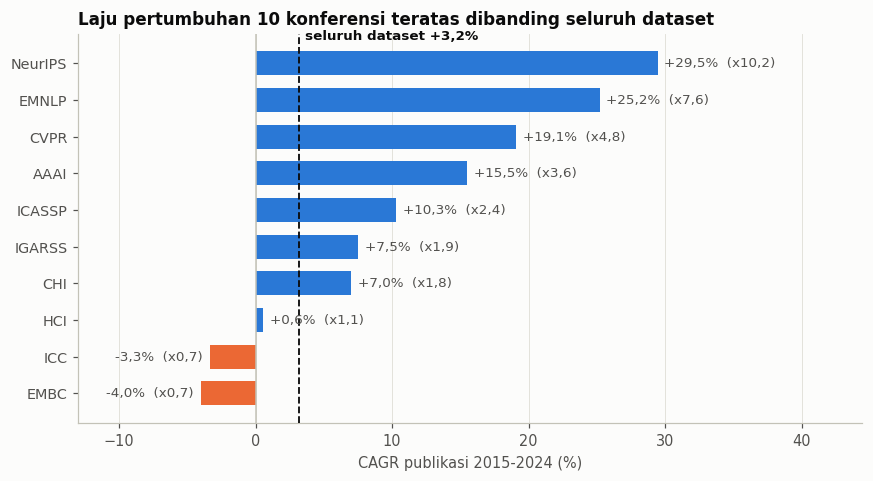

In [49]:
order = growth.sort_values("cagr_%")

fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.barh(np.arange(len(order)), order["cagr_%"], color=[CFG.BLUE if v >= 0 else CFG.ORANGE for v in order["cagr_%"]],
        height=0.66, zorder=2)
ax.axvline(0, color=CFG.BASELINE, lw=1)
ax.axvline(cagr * 100, color=CFG.INK, lw=1.2, ls="--", zorder=3)
ax.text(cagr * 100 + 0.4, len(order) - 0.35, f"seluruh dataset +{cagr * 100:.1f}%".replace(".", ","), fontsize=8.8, fontweight="bold")
for y, (_, row) in enumerate(order.iterrows()):
    ha, dx = ("left", 0.5) if row["cagr_%"] >= 0 else ("right", -0.5)
    ax.text(row["cagr_%"] + dx, y, f"{row['cagr_%']:+.1f}%  (x{row['kali_lipat']:.1f})".replace(".", ","),
            va="center", ha=ha, fontsize=8.8, color=CFG.INK_2)
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order["nama"], fontsize=9.4)
ax.set_xlim(order["cagr_%"].min() - 9, order["cagr_%"].max() + 15)
ax.set_xlabel("CAGR publikasi 2015-2024 (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Laju pertumbuhan 10 konferensi teratas dibanding seluruh dataset")
save_fig(fig, "t2_cagr_top10.png")

Untuk melihat pola yang sama pada 20 konferensi terbesar sekaligus, dipakai heatmap, yaitu chart yang dalam panduan Datawrapper cocok untuk menampilkan banyak kategori sepanjang waktu. Setiap sel adalah indeks jumlah paper terhadap rata-rata 2015-2017 konferensi itu sendiri (100 berarti sama dengan awal periode). Konferensi yang tidak tercatat pada salah satu tahun 2015-2017 dikeluarkan karena rata-rata awalnya tidak dapat dihitung secara adil, dan penggantinya diambil dari peringkat berikutnya. Biru berarti di atas awal periode, merah di bawahnya, dan kolom 2025 diberi arsiran karena belum lengkap.

Dikeluarkan karena tidak tercatat pada salah satu tahun 2015-2017: ['ICLR']


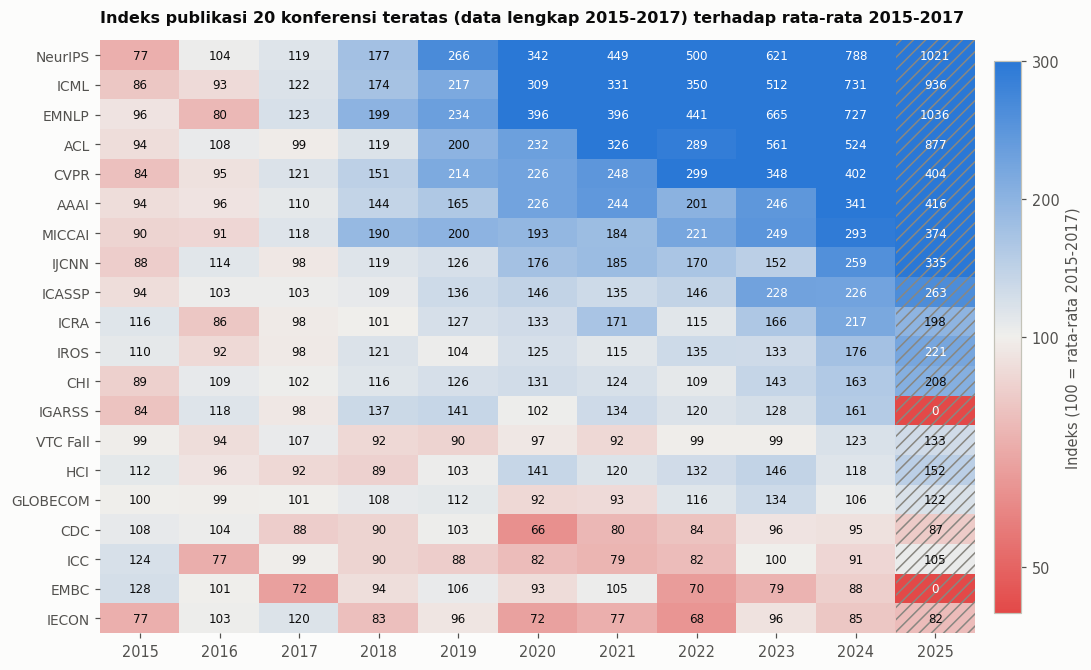

In [50]:
complete_base = trend.loc[pub_venue.index, 2015:2017].gt(0).all(axis=1)
excluded = [display_name(v) for v in pub_venue.head(20).index if not complete_base[v]]
top20_venues = list(pub_venue[complete_base].head(20).index)
print("Dikeluarkan karena tidak tercatat pada salah satu tahun 2015-2017:", excluded)
baseline = trend.loc[top20_venues, 2015:2017].mean(axis=1)
heat = trend.loc[top20_venues].div(baseline, axis=0) * 100
heat = heat.loc[heat[2024].sort_values(ascending=False).index]
save_table(heat.round(1), "t2_indeks_tren_top20.csv")

cmap = LinearSegmentedColormap.from_list("merah_netral_biru", ["#e34948", "#f0efec", "#2a78d6"])
norm = TwoSlopeNorm(vcenter=100, vmin=40, vmax=300)

fig, ax = plt.subplots(figsize=(10.8, 7.0))
image = ax.imshow(heat.values, cmap=cmap, norm=norm, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.values[i, j]
        dark = value > 210 or value < 55
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=7.8, color="#ffffff" if dark else CFG.INK, zorder=6)
ax.add_patch(Rectangle((heat.shape[1] - 1.5, -0.5), 1, heat.shape[0], fill=False, hatch="///", edgecolor=CFG.MUTED, lw=0, zorder=2))
ax.set_xticks(np.arange(heat.shape[1]))
ax.set_xticklabels(heat.columns.astype(int))
ax.set_yticks(np.arange(heat.shape[0]))
ax.set_yticklabels([display_name(v) for v in heat.index], fontsize=9)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02, ticks=[50, 100, 200, 300])
colorbar.set_label("Indeks (100 = rata-rata 2015-2017)")
ax.set_title("Indeks publikasi 20 konferensi teratas (data lengkap 2015-2017) terhadap rata-rata 2015-2017", pad=12, fontsize=10.5)
save_fig(fig, "t2_heatmap_tren_top20.png")

#### Insights

> Pertumbuhan terkonsentrasi pada konferensi kecerdasan buatan. NeurIPS tumbuh 10,2 kali (440 menjadi 4.494 paper pada 2024, CAGR 29,5%), EMNLP 7,6 kali (324 menjadi 2.450, CAGR 25,2%), CVPR 4,8 kali (CAGR 19,1%), dan AAAI 3,6 kali (CAGR 15,5%). Keempatnya jauh di atas CAGR seluruh dataset sebesar 3,2%.

> Konferensi dari bidang lain tumbuh lebih lambat atau menyusut. ICASSP tumbuh 2,4 kali (CAGR 10,3%), IGARSS 1,9 kali (7,5%), CHI 1,8 kali (7,0%), dan HCI hampir datar (1,1 kali, 0,6%). Dua konferensi justru menurun, yaitu ICC (0,7 kali, -3,3%) dan EMBC (0,7 kali, -4,0%).

> Akibatnya konsentrasi makin tinggi: porsi 10 konferensi teratas terhadap seluruh publikasi naik dari 7,0% (2015) menjadi 11,7% (2024), dan 12,9% pada 2025. Kenaikan ini sudah terlihat sejak 2017, jadi tidak semata-mata akibat data 2025 yang tidak lengkap.

> Heatmap pada 20 konferensi memperkuat pola tersebut. Konferensi pembelajaran mesin dan NLP (NeurIPS, ICML, EMNLP, ACL) berindeks 524 sampai 788 pada 2024 terhadap rata-rata 2015-2017, sedangkan IECON (85), EMBC (88), ICC (91), dan CDC (95) berada di bawah level awal. ICLR dikeluarkan dari heatmap karena tidak tercatat di DBLP pada 2015 dan 2016; sejak 2017 ICLR tumbuh dari 309 menjadi 2.454 paper pada 2024.

> Pada 2025, NeurIPS (5.823, +29,6%), EMNLP (3.491, +42,5%), dan AAAI (3.508, +21,7%) melanjutkan kenaikan, sedangkan IGARSS dan EMBC bernilai nol karena prosiding 2025 belum terindeks, bukan karena berhenti diselenggarakan.

## 6.4 Perbandingan Peringkat Publikasi dan Author Unik (Task 2.4)

Perbandingan dilakukan dalam tiga bentuk. Tabel memuat seluruh konferensi yang masuk 10 besar pada salah satu ukuran. Slope chart, jenis chart yang dalam panduan Datawrapper dipakai untuk melihat perubahan antara dua kondisi, menunjukkan bagaimana peringkat bergeser dari ukuran publikasi ke ukuran author unik. Scatter plot, jenis chart untuk hubungan dua ukuran, menunjukkan seluruh konferensi sekaligus beserta ukuran seberapa luas komunitas per paper.

In [51]:
union = list(top_pub.index) + [v for v in top_auth.index if v not in top_pub.index]
compare = venue_stats.loc[union, ["nama", "publikasi", "rank_publikasi", "author_unik", "rank_author",
                                  "paper_per_author", "author_unik_per_paper"]].copy()
compare["selisih_rank"] = compare["rank_publikasi"] - compare["rank_author"]
compare["masuk_10_besar"] = np.where(compare.index.isin(shared), "kedua ukuran",
                                     np.where(compare["rank_publikasi"] <= 10, "hanya publikasi", "hanya author unik"))
save_table(compare, "t2_perbandingan_peringkat.csv")

rho = venue_stats[["publikasi", "author_unik"]].corr(method="spearman").iloc[0, 1]
r_log = np.corrcoef(np.log10(venue_stats["publikasi"]), np.log10(venue_stats["author_unik"]))[0, 1]
print(f"Irisan 10 besar: {len(shared)} dari 10 venue | korelasi peringkat Spearman ({len(venue_stats):,} venue): {rho:.3f} | "
      f"korelasi log-log: {r_log:.3f}")
compare.round(2)

Irisan 10 besar: 8 dari 10 venue | korelasi peringkat Spearman (4,373 venue): 0.987 | korelasi log-log: 0.986


,nama,publikasi,rank_publikasi,author_unik,rank_author,paper_per_author,author_unik_per_paper,selisih_rank,masuk_10_besar
venue,,,,,,,,,
nips,NeurIPS,25455,1,57800,1,2.18,2.27,0,kedua ukuran
cvpr,CVPR,22751,2,47664,2,2.50,2.10,0,kedua ukuran
icassp,ICASSP,21606,3,42057,4,2.11,1.95,-1,kedua ukuran
hci,HCI,19912,4,37884,6,1.83,1.90,-2,kedua ukuran
igarss,IGARSS,19685,5,35229,7,2.64,1.79,-2,kedua ukuran
aaai,AAAI,19274,6,46437,3,1.83,2.41,3,kedua ukuran
chi,CHI,14832,7,29904,12,2.22,2.02,-5,hanya publikasi
emnlp,EMNLP,14813,8,33954,8,2.16,2.29,0,kedua ukuran
embc,EMBC,14676,9,39318,5,1.84,2.68,4,kedua ukuran


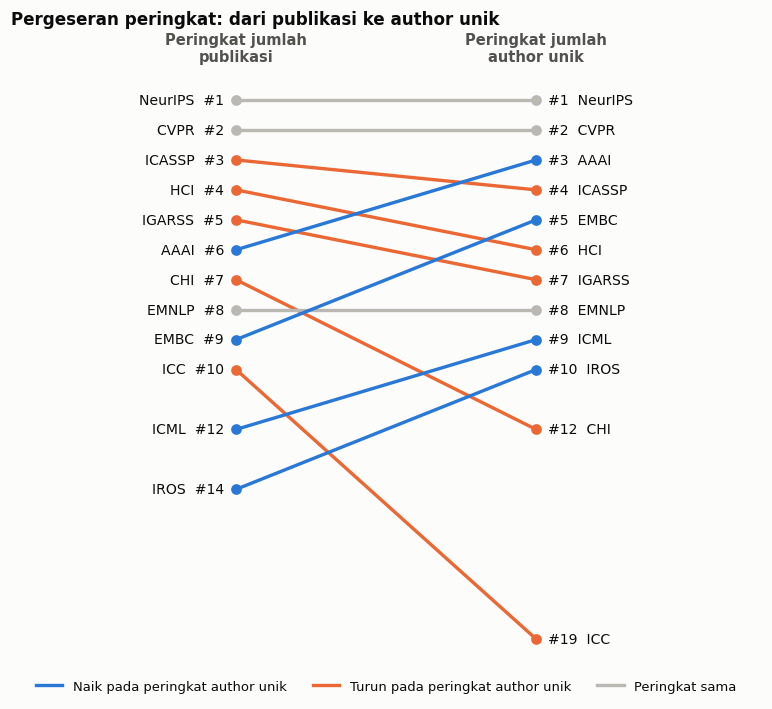

In [52]:
fig, ax = plt.subplots(figsize=(8.8, 7.0))
for venue, row in compare.iterrows():
    shift = row["selisih_rank"]
    color = CFG.BLUE if shift > 0 else (CFG.ORANGE if shift < 0 else CFG.GRAY)
    ax.plot([0, 1], [row["rank_publikasi"], row["rank_author"]], color=color, lw=2.2, marker="o", ms=6, zorder=3)
    ax.text(-0.04, row["rank_publikasi"], f"{row['nama']}  #{int(row['rank_publikasi'])}", ha="right", va="center", fontsize=9.2)
    ax.text(1.04, row["rank_author"], f"#{int(row['rank_author'])}  {row['nama']}", ha="left", va="center", fontsize=9.2)
ax.set_xlim(-0.75, 1.75)
ax.set_ylim(compare[["rank_publikasi", "rank_author"]].max().max() + 1, 0.2)
ax.axis("off")
ax.text(0, -0.2, "Peringkat jumlah\npublikasi", ha="center", va="bottom", fontsize=9.6, fontweight="bold", color=CFG.INK_2)
ax.text(1, -0.2, "Peringkat jumlah\nauthor unik", ha="center", va="bottom", fontsize=9.6, fontweight="bold", color=CFG.INK_2)
ax.set_title("Pergeseran peringkat: dari publikasi ke author unik", pad=34)
ax.legend(handles=[Line2D([], [], color=CFG.BLUE, lw=2.2, label="Naik pada peringkat author unik"),
                   Line2D([], [], color=CFG.ORANGE, lw=2.2, label="Turun pada peringkat author unik"),
                   Line2D([], [], color=CFG.GRAY, lw=2.2, label="Peringkat sama")],
          loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=3, fontsize=8.6)
save_fig(fig, "t2_slope_peringkat.png")

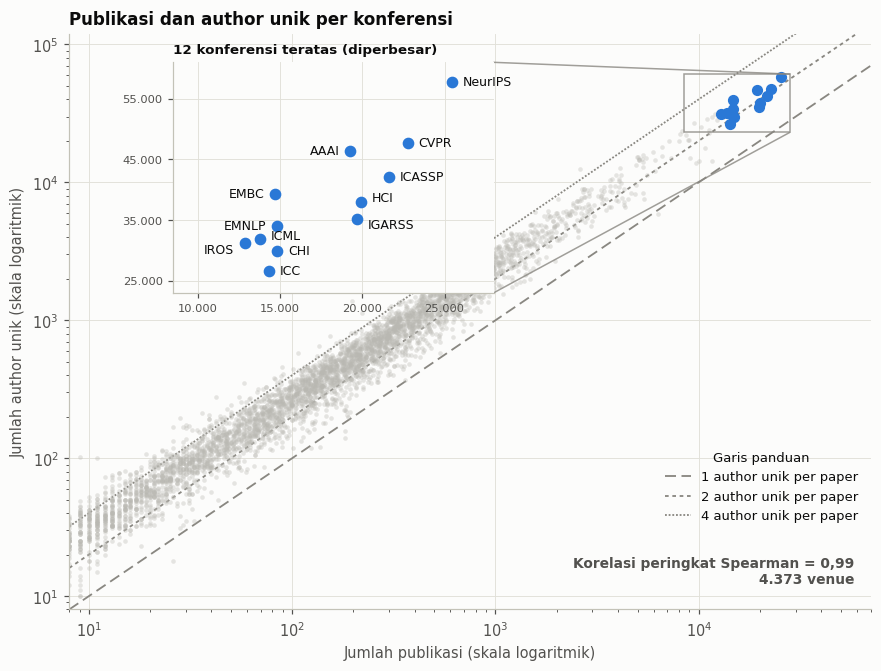

In [53]:
fig, ax = plt.subplots(figsize=(9.4, 6.8))
ax.scatter(venue_stats["publikasi"], venue_stats["author_unik"], s=9, color=CFG.GRAY, alpha=0.35, linewidths=0, zorder=2)
highlight = venue_stats.loc[union]
ax.scatter(highlight["publikasi"], highlight["author_unik"], s=40, color=CFG.BLUE, zorder=4)

guide_x = np.array([8, 7e4])
for k, style in ((1, (0, (6, 3))), (2, (0, (2, 2))), (4, (0, (1, 1)))):
    ax.plot(guide_x, k * guide_x, color=CFG.MUTED, lw=1.2, ls=style, zorder=1, label=f"{k} author unik per paper")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(8, 7e4)
ax.set_ylim(8, 1.2e5)
ax.set_xlabel("Jumlah publikasi (skala logaritmik)")
ax.set_ylabel("Jumlah author unik (skala logaritmik)")
ax.set_title("Publikasi dan author unik per konferensi")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.13), fontsize=8.6, title="Garis panduan", title_fontsize=8.6)
ax.text(0.98, 0.04, f"Korelasi peringkat Spearman = {rho:.2f}".replace(".", ",") + f"\n{fmt_id(len(venue_stats))} venue",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9, fontweight="bold", color=CFG.INK_2)

label_pos = {"nips": (7, 0, "left"), "cvpr": (7, 0, "left"), "aaai": (-7, 0, "right"), "icassp": (7, 0, "left"),
             "embc": (-7, 0, "right"), "hci": (7, 3, "left"), "igarss": (7, -4, "left"), "emnlp": (-7, 0, "right"),
             "icml": (7, 2, "left"), "iros": (-7, -5, "right"), "chi": (7, 0, "left"), "icc": (7, 0, "left")}
inset = ax.inset_axes([0.13, 0.55, 0.40, 0.40])
inset.scatter(highlight["publikasi"], highlight["author_unik"], s=44, color=CFG.BLUE, zorder=3)
for venue, row in highlight.iterrows():
    dx, dy, ha = label_pos.get(venue, (7, 0, "left"))
    inset.annotate(row["nama"], (row["publikasi"], row["author_unik"]), xytext=(dx, dy), textcoords="offset points",
                   ha=ha, va="center", fontsize=8.2)
inset.set_xlim(8.5e3, 28e3)
inset.set_ylim(23e3, 61e3)
inset.set_xticks([10e3, 15e3, 20e3, 25e3])
inset.set_yticks([25e3, 35e3, 45e3, 55e3])
inset.tick_params(labelsize=7.5)
inset.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_id(v)))
inset.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_id(v)))
inset.set_title("12 konferensi teratas (diperbesar)", fontsize=8.8, loc="left")
ax.indicate_inset_zoom(inset, edgecolor=CFG.MUTED, alpha=0.8)
save_fig(fig, "t2_scatter_publikasi_author.png")

#### Insights

> Peringkat publikasi dan peringkat author unik sangat selaras. Korelasi peringkat Spearman pada seluruh 4.373 konferensi adalah 0,987, dan 8 dari 10 konferensi teratas sama pada kedua ukuran. NeurIPS dan CVPR menempati posisi 1 dan 2 pada keduanya, dan EMNLP tetap di posisi 8.

> Perbedaan muncul di peringkat tengah. AAAI naik dari peringkat 6 ke 3 dan EMBC dari 9 ke 5 pada peringkat author unik, karena keduanya memiliki author unik per paper yang tinggi (2,41 dan 2,68). Sebaliknya CHI turun dari 7 ke 12 dan ICC dari 10 ke 19, sehingga keduanya keluar dari 10 besar author dan digantikan oleh ICML (dari peringkat 12 ke 9) dan IROS (dari 14 ke 10).

> Pada scatter plot, hampir semua konferensi berada di antara garis 1 dan 4 author unik per paper dan mengelompok di sekitar 2. Perbedaan peringkat karena itu berasal dari variasi rasio tersebut, bukan dari hubungan yang berbeda antara dua ukuran. ICC mengalami penurunan terbesar (9 peringkat), dan sekitar seperlima papernya (22,8%) adalah paper workshop (lihat 6.5).

## 6.5 Uji Sensitivitas terhadap Keputusan Venue

Venue diidentifikasi dari `key`, sehingga workshop dan acara pendamping ikut terhitung sebagai konferensi induknya. Agar kesimpulan peringkat tidak bergantung pada keputusan itu, peringkat dihitung ulang tanpa acara satelit. Acara satelit dikenali dari kata kunci pada `booktitle` (Workshop, `@`, Extended Abstracts, Companion, Doctoral, Tutorial, Demo, Poster, Student, Competition, dan Challenge). Pengenalan ini bersifat pendekatan.

Pendekatan lain, yaitu akhiran huruf pada `crossref` (misalnya `conf/cvpr/2011w`), juga diuji dan dibandingkan di tabel. Pendekatan itu ditinggalkan karena menandai volume Findings pada EMNLP dan ACL sebagai satelit, padahal Findings adalah bagian dari konferensi utama.

In [54]:
meta = pd.read_parquet(CFG.CLEAN_PARQUET, columns=["venue", "booktitle", "crossref"])
satellite_pattern = r"Workshop|@|Extended Abstracts|Companion|Doctoral|Tutorial|Demo|Poster|Student|Competition|Challenge"
satellite = meta["booktitle"].fillna("").str.contains(satellite_pattern, case=False)
satellite_crossref = meta["crossref"].fillna("").str.contains(r"/\d{4}[a-z]+\d*$")

pub_main = (~satellite).groupby(meta["venue"]).sum()
crossref_share = satellite_crossref.groupby(meta["venue"]).mean() * 100

sens = pd.DataFrame({"publikasi_seluruh_key": pub_venue, "publikasi_tanpa_satelit": pub_main}).fillna(0).astype(int)
sens["rank_seluruh_key"] = sens["publikasi_seluruh_key"].rank(ascending=False, method="min").astype(int)
sens["rank_tanpa_satelit"] = sens["publikasi_tanpa_satelit"].rank(ascending=False, method="min").astype(int)
sens["porsi_satelit_booktitle_%"] = (1 - sens["publikasi_tanpa_satelit"] / sens["publikasi_seluruh_key"]) * 100
sens["porsi_satelit_crossref_%"] = crossref_share
sens["nama"] = [display_name(v) for v in sens.index]
save_table(sens.sort_values("rank_seluruh_key"), "t2_sensitivitas_satelit.csv")

top10_without_satellite = set(sens.sort_values("rank_tanpa_satelit").head(10).index)
print(f"Paper dari acara satelit menurut booktitle: {satellite.sum():,} ({satellite.mean():.1%}) | menurut crossref: {satellite_crossref.sum():,} ({satellite_crossref.mean():.1%})")
print(f"Irisan 10 besar sebelum dan sesudah satelit dikeluarkan: {len(set(top_pub.index) & top10_without_satellite)} dari 10")
print("Masuk 10 besar:", sorted(display_name(v) for v in top10_without_satellite - set(top_pub.index)))
print("Keluar dari 10 besar:", sorted(display_name(v) for v in set(top_pub.index) - top10_without_satellite))
sens.sort_values("rank_seluruh_key").head(12)[["nama", "publikasi_seluruh_key", "publikasi_tanpa_satelit", "porsi_satelit_booktitle_%",
                                               "porsi_satelit_crossref_%", "rank_seluruh_key", "rank_tanpa_satelit"]].round(1)

Paper dari acara satelit menurut booktitle: 144,549 (7.2%) | menurut crossref: 179,393 (9.0%)
Irisan 10 besar sebelum dan sesudah satelit dikeluarkan: 8 dari 10
Masuk 10 besar: ['ICML', 'IROS']
Keluar dari 10 besar: ['CHI', 'ICC']


,nama,publikasi_seluruh_key,publikasi_tanpa_satelit,porsi_satelit_booktitle_%,porsi_satelit_crossref_%,rank_seluruh_key,rank_tanpa_satelit
venue,,,,,,,
nips,NeurIPS,25455,25178,1.1,1.6,1,1
cvpr,CVPR,22751,17422,23.4,23.4,2,6
icassp,ICASSP,21606,21125,2.2,2.2,3,2
hci,HCI,19912,19912,0.0,0.2,4,3
igarss,IGARSS,19685,19685,0.0,0.0,5,4
aaai,AAAI,19274,18435,4.4,4.4,6,5
chi,CHI,14832,8303,44.0,44.0,7,29
emnlp,EMNLP,14813,14067,5.0,39.9,8,8
embc,EMBC,14676,14676,0.0,0.0,9,7


#### Insights

> Peringkat teratas relatif kuat terhadap keputusan menggabungkan workshop. Setelah acara satelit dikeluarkan (144.549 paper atau 7,2% dataset), 8 dari 10 konferensi teratas tetap sama dan NeurIPS tetap nomor satu (25.178 paper). ICASSP naik ke peringkat 2, HCI ke 3, IGARSS ke 4, dan AAAI ke 5.

> Yang berubah adalah konferensi yang banyak memiliki acara pendamping. CVPR turun dari peringkat 2 ke 6 karena 23,4% papernya adalah workshop, ICC dari 10 ke 18 (22,8%), dan CHI dari 7 ke 29 karena 44,0% papernya berasal dari Extended Abstracts. ICML dan IROS masuk 10 besar sebagai gantinya.

> Karena itu pernyataan bahwa CVPR adalah konferensi paling populer kedua bergantung pada definisi. Pernyataan itu benar jika workshop dihitung sebagai bagian konferensi, sesuai pengelompokan DBLP, tetapi tidak benar jika hanya acara utama yang dihitung. Jawaban Task 2 memakai definisi berbasis `key`, dan hasil alternatifnya dilaporkan di sini.

> Pendekatan alternatif berbasis akhiran `crossref` ditolak karena menandai 39,9% paper EMNLP sebagai satelit, padahal kata kunci `booktitle` hanya menemukan 5,0%. Selisihnya adalah volume Findings, yang merupakan bagian dari konferensi utama.

## 6.6 Jawaban Pertanyaan Task 2

Tiga pertanyaan penutup Task 2 dijawab berdasarkan hasil pada subbagian 6.1 sampai 6.5. Jawaban memakai definisi venue berbasis `key`, dan dampak definisi lain dijelaskan pada subbagian 6.5.

#### Insights

> **Konferensi mana yang paling populer berdasarkan jumlah publikasi?** NeurIPS, dengan 25.455 paper atau 1,27% dari seluruh dataset 2015-2025, disusul CVPR (22.751) dan ICASSP (21.606). NeurIPS tetap nomor satu pada uji sensitivitas yang mengeluarkan workshop dan acara satelit.

> **Apakah konferensi dengan publikasi terbanyak juga memiliki author unik terbanyak?** Ya untuk yang teratas, tetapi tidak untuk seluruh daftar. NeurIPS nomor satu pada kedua ukuran (57.800 author unik), CVPR nomor dua pada keduanya, dan 8 dari 10 konferensi teratas sama. Korelasi peringkat pada seluruh venue sangat tinggi (Spearman 0,987). Perbedaan terjadi di peringkat tengah: AAAI dan EMBC lebih tinggi pada author unik, sedangkan CHI dan ICC lebih tinggi pada jumlah paper, sehingga ICC yang berada di peringkat 10 pada publikasi hanya berada di peringkat 19 pada author unik.

> **Bagaimana aktivitas publikasi berubah selama 2015-2025?** Jumlah publikasi keseluruhan tumbuh 32,7% dari 2015 ke 2024 (CAGR 3,2%), dengan penurunan 8,8% pada 2020. Pertumbuhan sangat tidak merata: NeurIPS, EMNLP, CVPR, dan AAAI tumbuh 3,6 sampai 10,2 kali, HCI hampir datar, dan ICC serta EMBC menurun. Akibatnya porsi 10 konferensi teratas naik dari 7,0% menjadi 11,7% pada 2024. Angka 2025 tidak dipakai untuk menyimpulkan tren karena sebagian konferensi dua tahunan tidak diadakan dan sebagian konferensi tahunan belum terindeks.

---

# Ringkasan dan Langkah Berikutnya <a name="7"></a>

---

Ringkasan berikut merangkum jawaban Task 1 dan Task 2, asumsi yang dipakai, keterbatasan yang perlu dinyatakan pada laporan, dan langkah berikutnya.

## 7.1 Ringkasan Hasil

| Task | Pertanyaan | Hasil utama | Bukti |
|---|---|---|---|
| 1.1 | Struktur dan jenis publikasi | DBLP adalah daftar datar 13.127.979 record dari sembilan jenis. `inproceedings` berjumlah 4.004.309, dan 2.004.202 di antaranya terbit pada 2015-2025 | 3.1 dan 3.2 |
| 1.2 dan 1.3 | Preprocessing | Enam tahap membuang 6.958 paper (0,35%), retensi 99,65%. Hasil akhir 1.997.244 paper dan 7.870.902 pasangan paper-author | 4.1 sampai 4.8 |
| 1.4 | Statistik dataset bersih | 1.997.244 publikasi, 1.821.757 author unik, 4.373 venue unik. Distribusi per tahun dan per konferensi sangat terkonsentrasi | 5.1 sampai 5.4 |
| 2.1 | Top 10 publikasi | NeurIPS, CVPR, ICASSP, HCI, IGARSS, AAAI, CHI, EMNLP, EMBC, ICC | 6.1 |
| 2.2 | Top 10 author unik | NeurIPS, CVPR, AAAI, ICASSP, EMBC, HCI, IGARSS, EMNLP, ICML, IROS | 6.2 |
| 2.3 | Tren per tahun | CAGR 3,2% per tahun, tetapi pertumbuhan terkonsentrasi pada konferensi AI dan NLP | 6.3 |
| 2.4 | Perbandingan peringkat | 8 dari 10 konferensi sama, korelasi peringkat 0,987 | 6.4 dan 6.5 |

## 7.2 Asumsi dan Keterbatasan

1. Venue diidentifikasi dari segmen kedua `key`, sehingga workshop dan acara pendamping ikut terhitung sebagai konferensi induknya. Acara satelit menurut kata kunci `booktitle` berjumlah 7,2% paper, dan dampaknya besar pada CVPR, CHI, dan ICC (subbagian 6.5).
2. Record bertag `inproceedings` yang `key`-nya bukan `conf/` (3.161 paper, 0,16%) dibuang, termasuk beberapa prosiding workshop kecil yang diarsipkan DBLP pada seri jurnal.
3. Data 2025 tidak lengkap. Sebagian konferensi dua tahunan tidak diadakan pada 2025 dan sebagian konferensi tahunan belum terindeks, sehingga 2025 tidak dipakai untuk menghitung tren.
4. Nama author umum tanpa sufiks (misalnya `Yang Liu` pada 332 venue) kemungkinan menggabungkan banyak orang. Sebanyak 7.573 kelompok nama yang hanya berbeda diakritik atau huruf besar-kecil tidak digabung.
5. Aturan duplikat berdasarkan judul, tahun, dan venue dapat menghapus sebagian paper berbeda yang berjudul generik, dengan dampak paling banyak 421 baris (0,02% data).
6. ICLR tidak tercatat di DBLP pada 2015 dan 2016, sehingga dikeluarkan dari analisis indeks pertumbuhan.
7. Popularitas hanya diukur dari aktivitas publikasi, bukan dari sitasi atau kualitas.

## 7.3 Langkah Berikutnya

1. Task 3: membentuk dua transactional database dari `paper_author.parquet`, yaitu berbasis author dan berbasis author-tahun, lalu menampilkan contoh transaksi, jumlah transaksi, dan distribusi item per transaksi.
2. Task 4: mengimplementasikan Apriori dan FP-Growth pada database berbasis author dengan minimum support 0,1%, 0,5%, 1%, dan 2%, lalu memvalidasi hasilnya dengan `mlxtend`.
3. Task 5 dan 6: membangkitkan association rules dengan minimum confidence 50% dan membandingkan performa kedua algoritma.
4. Analisis temporal: menjalankan mining per periode 2015-2017, 2018-2020, 2021-2023, dan 2024-2025 pada database berbasis author-tahun, dengan memperhitungkan keterbatasan data 2025.

## Referensi

- DBLP XML dump: https://dblp.org/xml/ (diunduh 19 November 2026).
- Ley, M. *DBLP XML*, dokumentasi struktur XML dan `key`: https://dblp.org/xml/docu/dblpxml.pdf
- Datawrapper, *A friendly guide to choosing a chart type*: https://www.datawrapper.de/blog/chart-types-guide